# UAS Bengkel Koding Data Science — Prediksi Keinginan Pindah Kerja

**Notebook terpadu, audit dan optimasi terkontrol Tahap 1–4**

Nama: ... | NIM: ...

**Cara menjalankan:** unggah `UAS_DS_BENGKOD.csv` ke panel Files Google Colab, buka notebook ini, lalu pilih Runtime → Run all. Gunakan runtime CPU; tuning Voting/KNN dan Random Forest memerlukan beberapa menit. Tidak perlu mengunggah hasil CSV dari notebook lama. Semua hasil dihitung ulang, bukan menyalin output lama.

1. EDA: struktur data, missing value, kategori, duplikasi, anomali, distribusi, korelasi, dan risiko kebocoran.
2. Direct modeling: Decision Tree, Random Forest, Voting (DT + KNN + GaussianNB), konversi minimal.
3. Preprocessing modeling: pembersihan, seleksi fitur, imputasi, scaling, encoding, balancing.
4. Hyperparameter tuning: GridSearchCV, Stratified 5-Fold (group-aware bila diperlukan), evaluasi dan parameter terbaik.
5. Ringkasan sembilan eksperimen, diagnostik tambahan, interpretasi, dan ekspor hasil.

**Catatan audit:** pada CSV sumber yang diperiksa, 25.000 baris mempunyai ID unik, tetapi 5.842 baris merupakan pengulangan profil lengkap jika ID diabaikan. Split acak lama menempatkan 1.781 baris uji dengan profil identik di latih. Hal ini merupakan kebocoran antar-partisi. Revisi mempertahankan data mentah untuk EDA, membuang hanya salinan identik (selain ID) untuk eksperimen, dan memastikan profil yang sama setelah normalisasi tidak tersebar antar-partisi. Seluruh skenario memakai partisi baru yang sama. Skor lama bukan pembanding langsung karena set uji berubah.

Asumsi penggunaan: prediksi pada saat profil dan progres pelatihan sudah tersedia, **sebelum** informasi resign/aktivitas melamar diketahui. Bila prediksi dimaksudkan saat pendaftaran, jam pelatihan, modul selesai, sertifikasi, dan variabel setelah pendaftaran harus ditinjau kembali. Metrik utama adalah F1 kelas 1, bukan semata accuracy.
Revisi terkontrol: tiga model dan sembilan eksperimen tetap. Tuning membandingkan balancing, hard/soft voting, dan threshold dari prediksi out-of-fold (OOF). Holdout historis sama dengan audit terdahulu; bukan validasi eksternal baru. Tidak ada algoritma tambahan.


## 0. Konfigurasi, library, dan validasi dataset

In [1]:
from pathlib import Path
from time import perf_counter
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy.stats import chi2_contingency
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.model_selection import (train_test_split, StratifiedKFold, StratifiedGroupKFold,
                                     GridSearchCV, ParameterGrid, cross_validate)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay,
    make_scorer, roc_auc_score, average_precision_score, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance
from sklearn.utils.validation import check_is_fitted
from IPython.display import display

RANDOM_STATE = 42
TEST_SIZE = .20
CV_FOLDS = 5
TARGET = 'ingin_pindah_kerja'
ID = 'id_peserta'
N_JOBS = 4  # Batasi paralelisme agar konsumsi RAM Colab terkendali.
OUTPUT_DIR = Path('hasil_optimasi_terkontrol')
OUTPUT_DIR.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)

paths = [Path('UAS_DS_BENGKOD.csv'), Path('/content/UAS_DS_BENGKOD.csv'),
         Path('upload/UAS_DS_BENGKOD.csv'), Path('data/Belajar grammar/UAS_DS_BENGKOD.csv')]
path = next((p for p in paths if p.is_file()), None)
if path is None:
    raise FileNotFoundError('Unggah UAS_DS_BENGKOD.csv ke panel Files Colab, lalu jalankan ulang.')
df = pd.read_csv(path)
EXPECTED_NUMERIC = ['indeks_pembangunan_kota', 'jam_pelatihan', 'skor_tes_awal',
    'jumlah_modul_selesai', 'skor_kepuasan_kerja', 'persentase_kenaikan_gaji',
    'jarak_rumah_ke_kantor_km', 'estimasi_gaji_bulanan_juta']
EXPECTED_TEXT = [ID, 'kode_kota', 'jenis_kelamin', 'pengalaman_relevan', 'status_kuliah',
    'pendidikan', 'jurusan', 'lama_pengalaman_thn', 'ukuran_perusahaan', 'tipe_perusahaan',
    'jeda_pindah_kerja_thn', 'tanggal_daftar', 'sumber_info', 'sudah_ajukan_resign',
    'kegiatan_ekstrakurikuler', 'akses_lamaran_linkedin', 'kode_departemen_asal', 'sertifikasi_it']
expected = set(EXPECTED_NUMERIC + EXPECTED_TEXT + [TARGET])
assert set(df.columns) == expected, f'Skema berbeda: kurang={expected-set(df.columns)}, tambahan={set(df.columns)-expected}'
assert df[TARGET].notna().all() and set(df[TARGET].unique()) == {0,1}, 'Target wajib biner 0/1 tanpa missing.'
assert df[ID].notna().all(), 'ID kosong perlu diaudit.'
assert all(pd.api.types.is_numeric_dtype(df[c]) for c in EXPECTED_NUMERIC), 'Tipe data numerik mentah berubah; audit CSV.'
print('Pandas:', pd.__version__, '| scikit-learn:', sklearn.__version__)
print('Dataset asli:', df.shape)
display(df.head())

Pandas: 2.2.3 | scikit-learn: 1.6.1
Dataset asli: (25000, 27)


,id_peserta,kode_kota,indeks_pembangunan_kota,jenis_kelamin,pengalaman_relevan,status_kuliah,pendidikan,jurusan,lama_pengalaman_thn,ukuran_perusahaan,tipe_perusahaan,jeda_pindah_kerja_thn,jam_pelatihan,ingin_pindah_kerja,tanggal_daftar,sumber_info,skor_tes_awal,jumlah_modul_selesai,sudah_ajukan_resign,skor_kepuasan_kerja,persentase_kenaikan_gaji,jarak_rumah_ke_kantor_km,kegiatan_ekstrakurikuler,akses_lamaran_linkedin,estimasi_gaji_bulanan_juta,kode_departemen_asal,sertifikasi_it
0,PST-000001,K46,0.762,Laki-laki,Ada,Tidak kuliah,S1,STEM,10,1000-4999,Swasta (PT),4,83.0,0,4/8/2023,Iklan,72.9,11,Belum,88.3,15.38,7.0,Tidak Ada,Tidak Pernah,18.61,HR_JTM_313,Tidak Ada
1,PST-000002,K105,0.794,Laki-laki,Ada,Tidak kuliah,S1,STEM,17,<10,Swasta (PT),4,118.0,0,7/10/2024,Iklan,44.5,13,Sudah,70.1,2.06,38.0,Olahraga,Sering,31.81,OPS-DKI-619,Tidak Ada
2,PST-000003,K114,0.926,Laki-laki,Tidak ada,Kuliah penuh waktu,S1,STEM,14,<10,Startup tahap awal,1,28.0,1,4/12/2023,Instagram,75.0,5,Sudah,NaN,0.17,49.0,Seni,Sering,25.82,FIN-JTM-868,Tidak Ada
3,PST-000004,K145,0.555,Laki-laki,Ada,Tidak kuliah,s1,stem,5,Oct-49,Startup berpendanaan,2,70.0,0,5/16/2023,LinkedIn,60.0,7,Belum,NaN,2.92,18.0,Olahraga,Kadang,9.28,HR-BTN-840,Tidak Ada
4,PST-000005,K91,0.691,Laki-laki,Tidak ada,Tidak kuliah,S2,STEM,10,10000+,Swasta (PT),2,86.0,0,10/4/2023,Teman,69.3,13,Sudah,85.3,16.05,33.0,Seni,Tidak Pernah,20.86,IT-BTN-335,Data Science Bootcamp


# Tahap 1 — Exploratory Data Analysis (EDA)
## 1. Struktur, statistik deskriptif, dan kualitas data mentah
Satu baris merepresentasikan catatan profil peserta, target 1 = ingin pindah kerja. Audit mentah hanya deskriptif; analisis hubungan fitur-target dilakukan pada data latih setelah partisi dibuat.

In [2]:
df.info()
display(df.describe().T)
display(df.describe(include=['object', 'string']).T)
schema = pd.DataFrame({'tipe': df.dtypes.astype(str), 'non_null': df.notna().sum(),
                       'unik': df.nunique(), 'missing': df.isna().sum()})
display(schema)
print('Prediktor numerik:', len(EXPECTED_NUMERIC), '| kategorikal/format teks:', len(EXPECTED_TEXT))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 27 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   id_peserta                  25000 non-null  object 
 1   kode_kota                   25000 non-null  object 
 2   indeks_pembangunan_kota     24479 non-null  float64
 3   jenis_kelamin               19056 non-null  object 
 4   pengalaman_relevan          25000 non-null  object 
 5   status_kuliah               24489 non-null  object 
 6   pendidikan                  24317 non-null  object 
 7   jurusan                     21257 non-null  object 
 8   lama_pengalaman_thn         24916 non-null  object 
 9   ukuran_perusahaan           17281 non-null  object 
 10  tipe_perusahaan             16939 non-null  object 
 11  jeda_pindah_kerja_thn       24449 non-null  object 
 12  jam_pelatihan               24532 non-null  float64
 13  ingin_pindah_kerja          250

,count,mean,std,min,25%,50%,75%,max
indeks_pembangunan_kota,24479.0,0.855084,0.464598,0.448,0.74,0.91,0.92,9.49
jam_pelatihan,24532.0,69.665702,110.197890,-332.000,23.00,47.00,90.00,4200.00
ingin_pindah_kerja,25000.0,0.250520,0.433321,0.000,0.00,0.00,1.00,1.00
skor_tes_awal,24251.0,62.703715,26.458699,11.100,52.40,62.00,71.50,999.00
jumlah_modul_selesai,25000.0,8.206680,7.607972,0.000,3.00,6.00,11.00,44.00
skor_kepuasan_kerja,23662.0,63.634160,18.607244,30.000,45.90,69.30,79.70,90.00
persentase_kenaikan_gaji,23609.0,9.703599,6.663183,0.000,2.89,11.37,15.71,20.00
jarak_rumah_ke_kantor_km,23762.0,30.354221,17.356519,1.000,15.00,30.00,45.00,60.00
estimasi_gaji_bulanan_juta,24916.0,20.181170,10.339251,0.000,11.69,17.89,28.76,43.85


,count,unique,top,freq
id_peserta,25000,25000,PST-000001,1
kode_kota,25000,239,K103,5577
jenis_kelamin,19056,6,Laki-laki,17029
pengalaman_relevan,25000,2,Ada,18019
status_kuliah,24489,12,Tidak kuliah,17316
pendidikan,24317,18,S1,14548
jurusan,21257,26,STEM,18177
lama_pengalaman_thn,24916,42,>20,4276
ukuran_perusahaan,17281,8,50-99,4005
tipe_perusahaan,16939,9,Swasta (PT),12675


,tipe,non_null,unik,missing
id_peserta,object,25000,25000,0
kode_kota,object,25000,239,0
indeks_pembangunan_kota,float64,24479,119,521
jenis_kelamin,object,19056,6,5944
pengalaman_relevan,object,25000,2,0
status_kuliah,object,24489,12,511
pendidikan,object,24317,18,683
jurusan,object,21257,26,3743
lama_pengalaman_thn,object,24916,42,84
ukuran_perusahaan,object,17281,8,7719


Prediktor numerik: 8 | kategorikal/format teks: 18


## 2. Missing value dan placeholder

,jumlah_kosong,placeholder,total_kosong_efektif,persentase_kosong,persentase_efektif
tipe_perusahaan,8061,126,8187,32.24,32.75
ukuran_perusahaan,7719,0,7719,30.88,30.88
jenis_kelamin,5944,214,6158,23.78,24.63
jurusan,3743,221,3964,14.97,15.86
persentase_kenaikan_gaji,1391,0,1391,5.56,5.56
skor_kepuasan_kerja,1338,0,1338,5.35,5.35
jarak_rumah_ke_kantor_km,1238,0,1238,4.95,4.95
pendidikan,683,256,939,2.73,3.76
skor_tes_awal,749,0,749,3.00,3.00
jeda_pindah_kerja_thn,551,0,551,2.20,2.20


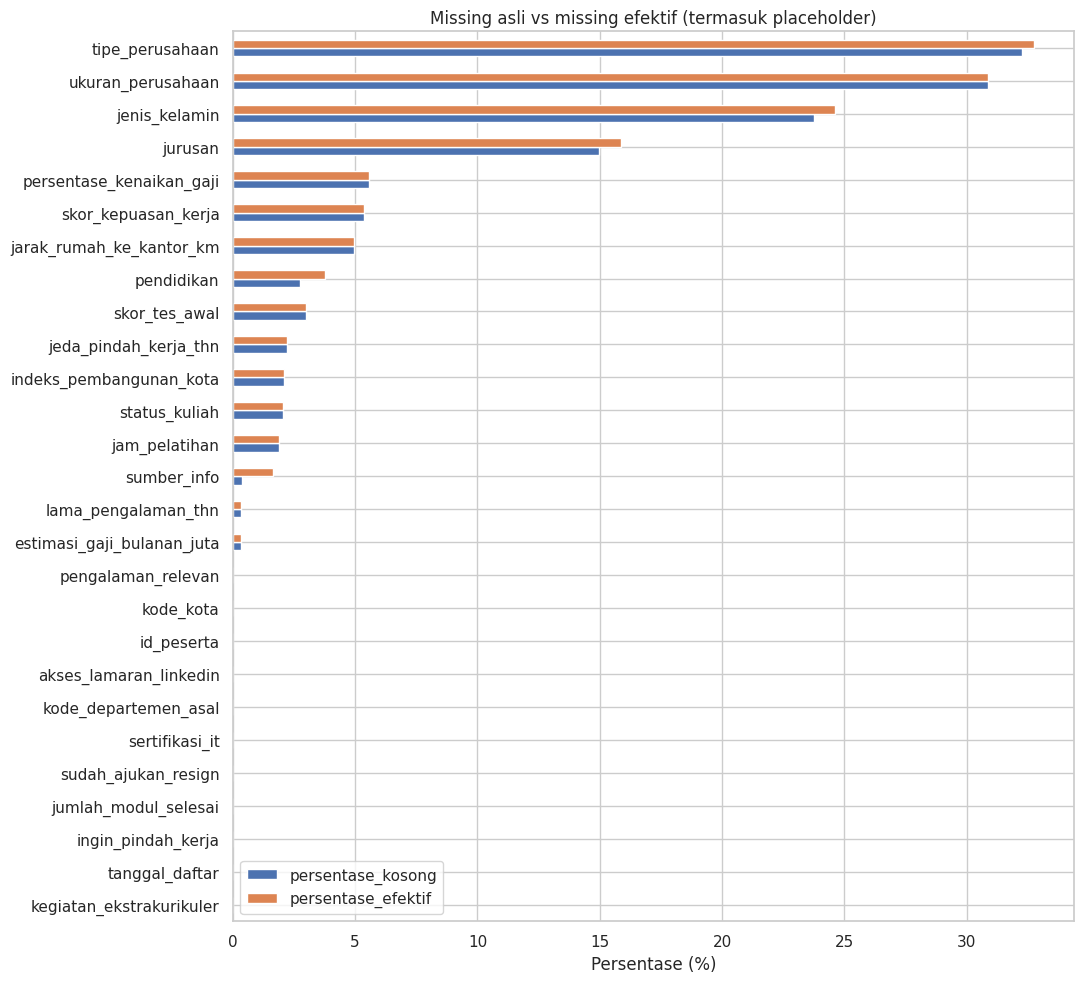

Baris dengan setidaknya satu NaN: 15804
Baris dengan setidaknya satu missing efektif: 16268


In [3]:
PLACEHOLDER = {'?', '-', 'tidak diisi', '', 'n/a', 'na', 'null', 'nan'}
def normalize_text(series):
    s = series.astype('string').str.strip().str.lower().str.replace(r'\s+', ' ', regex=True)
    return s.mask(s.isin(PLACEHOLDER))

placeholder_count = pd.Series(0, index=df.columns)
for col in EXPECTED_TEXT:
    s = df[col].astype('string').str.strip().str.lower()
    placeholder_count[col] = int(s.isin(PLACEHOLDER).sum())
missing = pd.DataFrame({'jumlah_kosong': df.isna().sum(), 'placeholder': placeholder_count})
missing['total_kosong_efektif'] = missing.sum(axis=1)
missing['persentase_kosong'] = missing['jumlah_kosong']/len(df)*100
missing['persentase_efektif'] = missing['total_kosong_efektif']/len(df)*100
missing = missing.sort_values('persentase_efektif', ascending=False)
display(missing.round(2))
ax = missing[['persentase_kosong','persentase_efektif']].sort_values('persentase_efektif').plot.barh(figsize=(11,10))
ax.set(title='Missing asli vs missing efektif (termasuk placeholder)', xlabel='Persentase (%)')
plt.tight_layout(); plt.show()
print('Baris dengan setidaknya satu NaN:', df.isna().any(axis=1).sum())
print('Baris dengan setidaknya satu missing efektif:', pd.DataFrame({
    c: normalize_text(df[c]).isna() if c in EXPECTED_TEXT else df[c].isna()
    for c in df}).any(axis=1).sum())

## 3. Duplikasi: baris lengkap, ID, dan profil tanpa ID

In [4]:
raw_predictors = [c for c in df if c not in [ID, TARGET]]
duplicate_subset = [c for c in df if c != ID]  # termasuk target, untuk exact dedup
raw_groups = pd.util.hash_pandas_object(df[raw_predictors], index=False)
duplicates = pd.DataFrame({
    'Pemeriksaan': ['Baris lengkap', 'ID peserta', 'Profil + target tanpa ID', 'Profil tanpa ID dan target'],
    'Duplikat tambahan': [df.duplicated().sum(), df[ID].duplicated().sum(),
                          df.duplicated(duplicate_subset).sum(), df.duplicated(raw_predictors).sum()]
})
display(duplicates)
print('Seluruh anggota grup profil berulang:', df.duplicated(raw_predictors, keep=False).sum())
print('Grup profil dengan target bertentangan:', df.groupby(raw_groups)[TARGET].nunique().gt(1).sum())
print('Distribusi ukuran grup profil:')
display(raw_groups.value_counts().value_counts().sort_index().rename('jumlah_grup'))

# Reproduksi diagnostik split lama, TIDAK dipakai untuk modeling.
old_tr, old_te = train_test_split(df.index, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=df[TARGET])
old_overlap = int(raw_groups.loc[old_te].isin(raw_groups.loc[old_tr]).sum())
print(f'Profil test lama dengan padanan di train: {old_overlap:,} dari {len(old_te):,} ({old_overlap/len(old_te):.2%})')
if df[ID].duplicated().any():
    raise ValueError('ID berulang perlu resolusi sebelum split, agar peserta yang sama tidak bocor.')

,Pemeriksaan,Duplikat tambahan
0,Baris lengkap,0
1,ID peserta,0
2,Profil + target tanpa ID,5842
3,Profil tanpa ID dan target,5842


Seluruh anggota grup profil berulang: 10855
Grup profil dengan target bertentangan: 0
Distribusi ukuran grup profil:


,jumlah_grup
count,
1,14145
2,4264
3,674
4,71
5,3
6,1


Profil test lama dengan padanan di train: 1,781 dari 5,000 (35.62%)


**Interpretasi:** ID berbeda bukan bukti bahwa profil independen. Profil yang sama persis pada puluhan atribut sangat kuat mengindikasikan salinan. Revisi menghapus salinan profil+target identik, tanpa menghapus nilai missing atau kelas minoritas secara selektif. Profil identik dengan target berbeda tidak dihapus secara sewenang-wenang, tetapi dijaga satu grup. Jika dataset operasional memiliki peserta berbeda dengan profil identik yang sah, deduplikasi perlu konfirmasi sumber dan group split tetap diperlukan.

## 4. Konsistensi kategori, format, dan kardinalitas

In [5]:
category_audit = []
for col in EXPECTED_TEXT:
    normalized = normalize_text(df[col])
    category_audit.append({'kolom': col, 'kategori_asli': df[col].nunique(),
        'kategori_normalisasi': normalized.nunique(), 'placeholder': placeholder_count[col],
        'rasio_unik': df[col].nunique()/len(df)})
display(pd.DataFrame(category_audit).sort_values('kategori_asli', ascending=False))
for col in ['jenis_kelamin','status_kuliah','pendidikan','jurusan','lama_pengalaman_thn',
            'ukuran_perusahaan','tipe_perusahaan','sumber_info','jeda_pindah_kerja_thn','sertifikasi_it']:
    print(col)
    display(df[col].value_counts(dropna=False).head(50))

,kolom,kategori_asli,kategori_normalisasi,placeholder,rasio_unik
0,id_peserta,25000,25000,0,1.00000
16,kode_departemen_asal,14944,14944,0,0.59776
11,tanggal_daftar,700,700,0,0.02800
1,kode_kota,239,123,0,0.00956
7,lama_pengalaman_thn,42,42,0,0.00168
6,jurusan,26,6,221,0.00104
12,sumber_info,23,5,308,0.00092
17,sertifikasi_it,22,22,0,0.00088
5,pendidikan,18,5,256,0.00072
4,status_kuliah,12,3,0,0.00048


jenis_kelamin


,count
jenis_kelamin,
Laki-laki,17029
NaN,5944
Perempuan,1577
Lainnya,236
?,84
tidak diisi,67
-,63


status_kuliah


,count
status_kuliah,
Tidak kuliah,17316
Kuliah penuh waktu,4718
Kuliah paruh waktu,1461
NaN,511
TIDAK KULIAH,256
Tidak kuliah,246
tidak kuliah,235
kuliah penuh waktu,64
Kuliah penuh waktu,63


pendidikan


... (11 outputs left out)

jeda_pindah_kerja_thn


,count
jeda_pindah_kerja_thn,
1,10489
>4,4291
2,3768
Belum pernah,3200
3,1361
4,1340
NaN,551


sertifikasi_it


,count
sertifikasi_it,
Tidak Ada,19955
Data Science Bootcamp,3833
Experiment Design Pro,72
SQL Performance Speci,71
ML Ops Foundations,70
NLP Engineer Basic,70
Data Ethics Officer,69
Cloud ETL Associate,68
AutoML Practitioner,66


## 5. Anomali numerik, outlier, dan tanggal

,jumlah
indeks di luar 0–1,83
jam pelatihan negatif,38
jam pelatihan > 1000 (kandidat outlier),46
skor tes di luar 0–100 (asumsi),66
skor kepuasan di luar 0–100 (asumsi),0
modul negatif,0
jarak negatif,0
gaji negatif,0


Tanggal gagal konversi: 0 | rentang: 2023-01-01 00:00:00 2024-11-30 00:00:00
Format pengalaman: ['10' '17' '14' '5' '7' '13' '4 tahun' '3' '11' '>20' '8' '2' '4' '19'
 '16' '1' '15' '9' '14 tahun' '6' '12' '<1' '18' nan '10 tahun' '15 tahun'
 '20' '1 tahun' '8 tahun' '5 tahun' '13 tahun' '7 tahun' '11 tahun'
 '9 tahun' '16 tahun' '2 tahun' '12 tahun' '6 tahun' '3 tahun' '18 tahun'
 '19 tahun' '17 tahun' '20 tahun']
Format ukuran perusahaan: ['1000-4999' '<10' 'Oct-49' '10000+' '50-99' nan '5000-9999' '500-999'
 '100-500']


,Q1,Q3,batas_bawah_IQR,batas_atas_IQR,kandidat_outlier_IQR
jam_pelatihan,23.00,90.00,-77.500,190.500,1285
jumlah_modul_selesai,3.00,11.00,-9.000,23.000,1227
skor_tes_awal,52.40,71.50,23.750,100.150,143
indeks_pembangunan_kota,0.74,0.92,0.470,1.190,101
skor_kepuasan_kerja,45.90,79.70,-4.800,130.400,0
persentase_kenaikan_gaji,2.89,15.71,-16.340,34.940,0
jarak_rumah_ke_kantor_km,15.00,45.00,-30.000,90.000,0
estimasi_gaji_bulanan_juta,11.69,28.76,-13.915,54.365,0


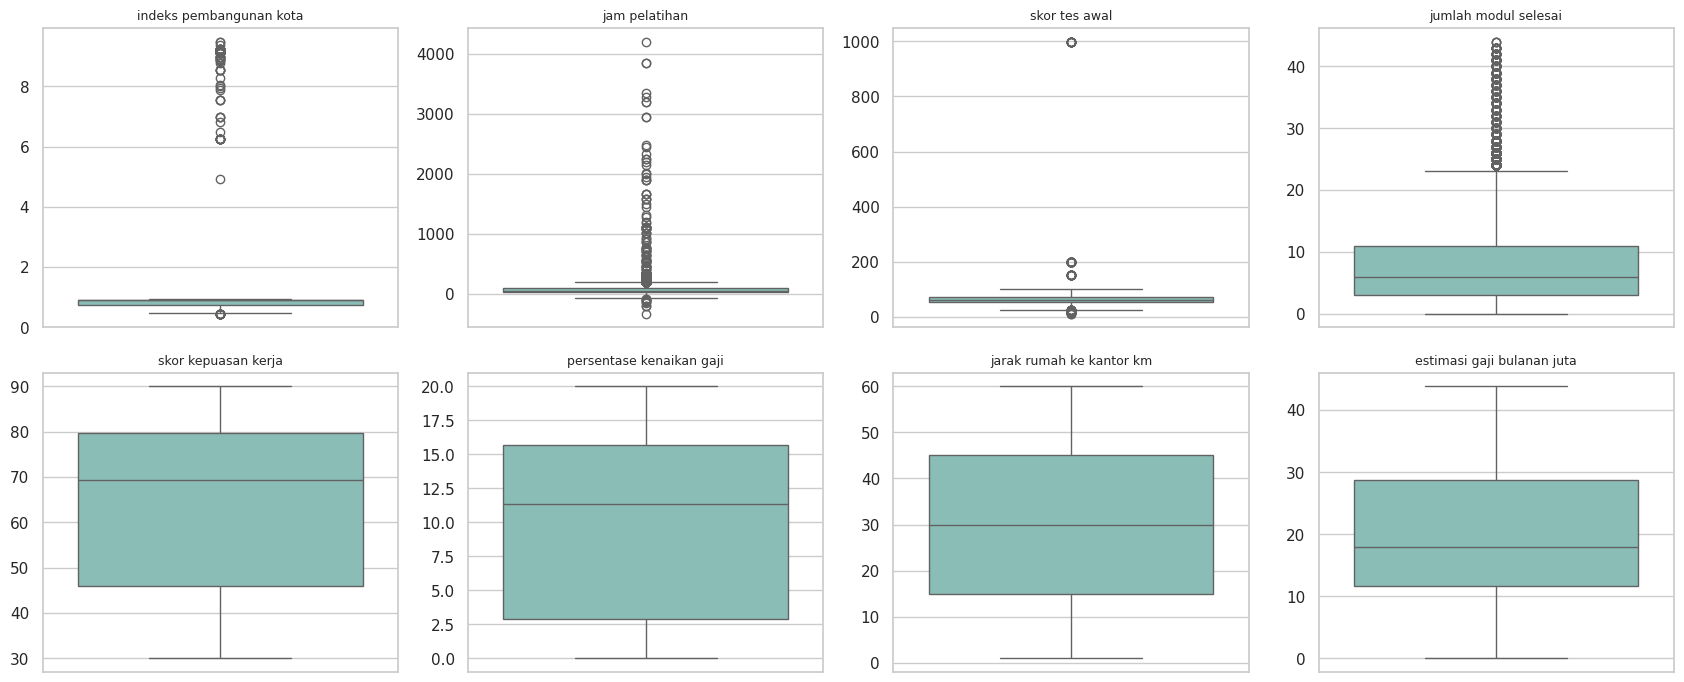

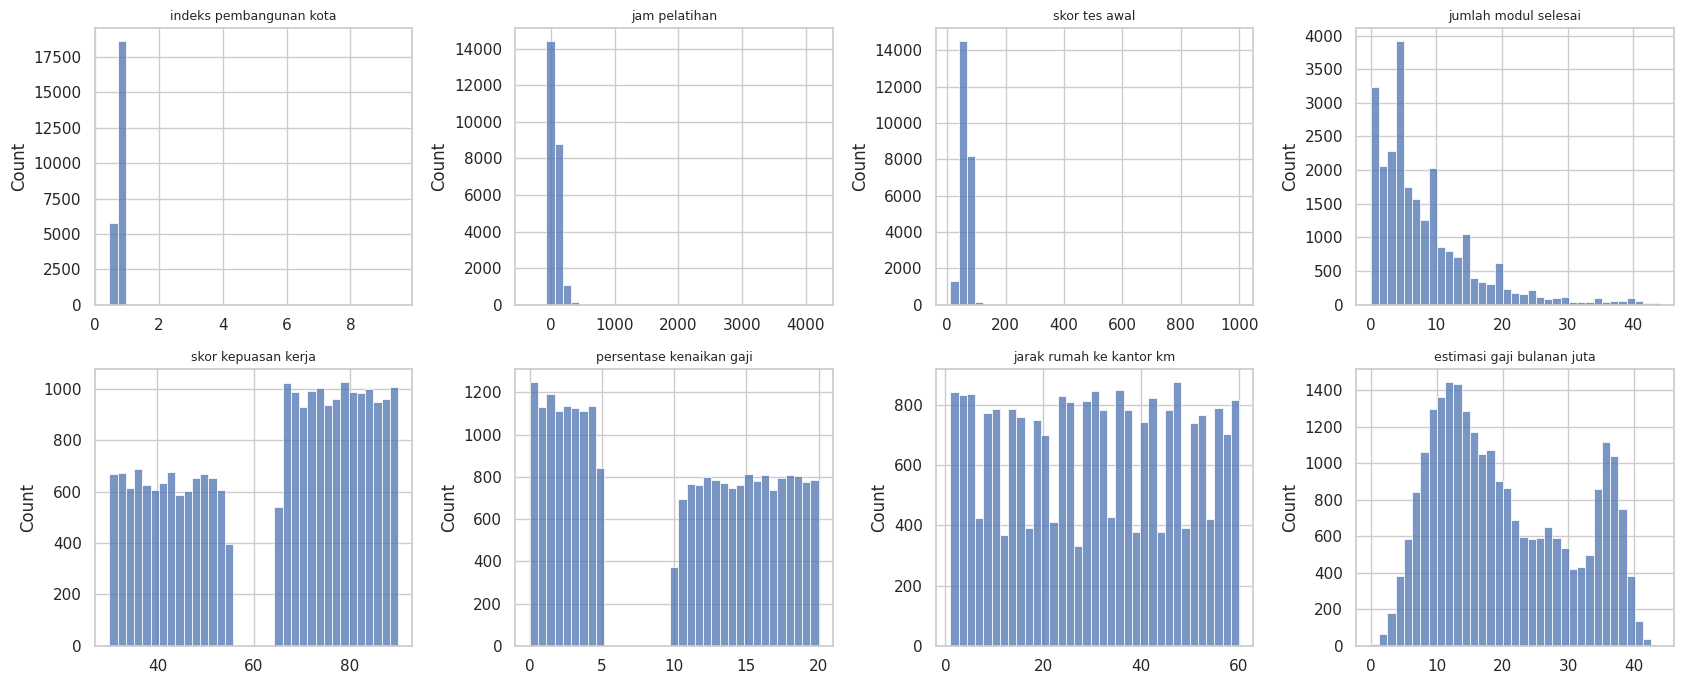

In [6]:
rules = {
    'indeks di luar 0–1': df['indeks_pembangunan_kota'].notna() & ~df['indeks_pembangunan_kota'].between(0,1),
    'jam pelatihan negatif': df['jam_pelatihan'] < 0,
    'jam pelatihan > 1000 (kandidat outlier)': df['jam_pelatihan'] > 1000,
    'skor tes di luar 0–100 (asumsi)': df['skor_tes_awal'].notna() & ~df['skor_tes_awal'].between(0,100),
    'skor kepuasan di luar 0–100 (asumsi)': df['skor_kepuasan_kerja'].notna() & ~df['skor_kepuasan_kerja'].between(0,100),
    'modul negatif': df['jumlah_modul_selesai'] < 0,
    'jarak negatif': df['jarak_rumah_ke_kantor_km'] < 0,
    'gaji negatif': df['estimasi_gaji_bulanan_juta'] < 0,
}
display(pd.Series({name: int(mask.sum()) for name, mask in rules.items()}, name='jumlah'))
dates = pd.to_datetime(df['tanggal_daftar'], format='%m/%d/%Y', errors='coerce')
print('Tanggal gagal konversi:', dates.isna().sum(), '| rentang:', dates.min(), dates.max())
print('Format pengalaman:', df['lama_pengalaman_thn'].unique())
print('Format ukuran perusahaan:', df['ukuran_perusahaan'].unique())
numeric = df[EXPECTED_NUMERIC]
q1, q3 = numeric.quantile(.25), numeric.quantile(.75)
iqr = q3-q1
outlier_summary = pd.DataFrame({'Q1':q1,'Q3':q3,'batas_bawah_IQR':q1-1.5*iqr,
    'batas_atas_IQR':q3+1.5*iqr,
    'kandidat_outlier_IQR':((numeric<q1-1.5*iqr)|(numeric>q3+1.5*iqr)).sum()})
display(outlier_summary.sort_values('kandidat_outlier_IQR',ascending=False))
fig, axes = plt.subplots(2,4,figsize=(17,7))
for col,ax in zip(EXPECTED_NUMERIC,axes.flat):
    sns.boxplot(y=df[col], ax=ax, color='#83C5BE')
    ax.set_title(col.replace('_',' '),fontsize=9); ax.set_ylabel('')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(2,4,figsize=(17,7))
for col,ax in zip(EXPECTED_NUMERIC,axes.flat):
    sns.histplot(df[col].dropna(),bins=35,ax=ax)
    ax.set_title(col.replace('_',' '),fontsize=9); ax.set_xlabel('')
plt.tight_layout(); plt.show()

IQR mengidentifikasi nilai ekstrem statistik, bukan memastikan kesalahan. Nilai mustahil (misal indeks >1, durasi negatif) menjadi missing. Skala skor 0–100 dan perbaikan `Oct-49` → `10-49` merupakan asumsi domain yang perlu dikonfirmasi. Persentase kenaikan gaji tidak dipaksa maksimum 20 hanya berdasarkan observasi; penurunan gaji dapat valid. Nilai gaji 0 juga tidak otomatis dihapus.

## 6. Distribusi target sebelum deduplikasi

,jumlah,persentase
ingin_pindah_kerja,,
0,18737,74.95
1,6263,25.05


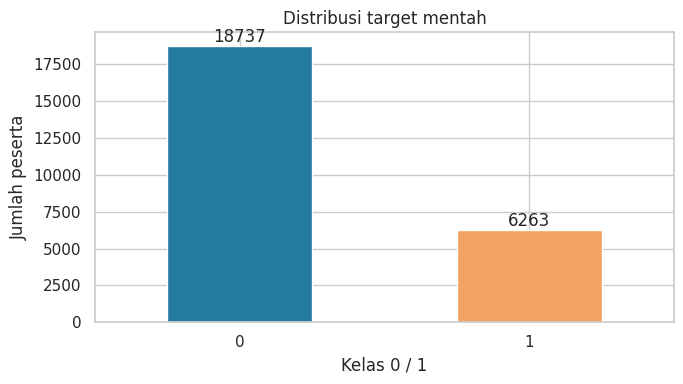

Accuracy mayoritas: 0.74948


In [7]:
target = df[TARGET]
distribution = pd.DataFrame({'jumlah':target.value_counts().sort_index(),
    'persentase':target.value_counts(normalize=True).sort_index()*100})
display(distribution.round(2))
ax = distribution['jumlah'].plot.bar(figsize=(7,4),color=['#247BA0','#F4A261'],rot=0)
ax.set(title='Distribusi target mentah',xlabel='Kelas 0 / 1',ylabel='Jumlah peserta')
ax.bar_label(ax.containers[0]); plt.tight_layout(); plt.show()
print('Accuracy mayoritas:', distribution['persentase'].max()/100)

## 7. Aturan normalisasi deterministik dan pembagian data tunggal
Fungsi ini juga dipakai oleh pipeline Tahap 3–4. **Tidak belajar dari data** (tidak ada median, kuantil, kategori frekuensi atau target). Digunakan sebelum split hanya untuk menemukan profil identik pada representasi aman, bukan untuk fit model. Data mentah tetap tidak diubah.

ID dan kode departemen lengkap dikeluarkan karena identitas/kardinalitas; resign dan akses lamaran dikeluarkan karena asumsi waktu prediksi. `jeda_pindah_kerja_thn` tetap kategori agar "belum pernah" berbeda dari nol tahun. Dua indikator menjaga informasi pengalaman tersensor `<1` / `>20` selain proksi numerik; tanggal menjadi tahun dan bulan.

In [8]:
DROP_FEATURES = [ID,'kode_departemen_asal','sudah_ajukan_resign','akses_lamaran_linkedin']
def clean_features(frame):
    # Menolak target sebagai input agar tidak tidak sengaja ikut transformasi.
    if TARGET in frame.columns:
        raise ValueError('Target tidak boleh masuk clean_features.')
    a = frame.copy().drop(columns=DROP_FEATURES, errors='ignore')
    for col in a.select_dtypes(exclude='number').columns:
        s = normalize_text(a[col])
        a[col] = s.astype(object).where(s.notna(),np.nan)
    a['ukuran_perusahaan'] = a['ukuran_perusahaan'].replace({'oct-49':'10-49'})
    exp = a['lama_pengalaman_thn'].astype('string').str.replace(r'\s*tahun$', '', regex=True).str.strip()
    a['pengalaman_kurang_1'] = exp.eq('<1').fillna(False).astype(float)
    a['pengalaman_lebih_20'] = exp.eq('>20').fillna(False).astype(float)
    a['lama_pengalaman_thn'] = pd.to_numeric(exp.replace({'<1':'0.5','>20':'21'}),errors='coerce').astype(float)
    a['lama_pengalaman_thn'] = a['lama_pengalaman_thn'].where(a['lama_pengalaman_thn']>=0)
    dates = pd.to_datetime(a.pop('tanggal_daftar'),format='%m/%d/%Y',errors='coerce')
    a['tahun_daftar'] = dates.dt.year.astype(float)
    a['bulan_daftar'] = dates.dt.month.astype(float)
    for col in EXPECTED_NUMERIC:
        a[col] = pd.to_numeric(a[col], errors='coerce').replace([np.inf,-np.inf],np.nan)
    for col, lo, hi in [('indeks_pembangunan_kota',0,1),('skor_tes_awal',0,100),('skor_kepuasan_kerja',0,100)]:
        a[col] = a[col].where(a[col].between(lo,hi))
    for col in ['jam_pelatihan','jumlah_modul_selesai','jarak_rumah_ke_kantor_km','estimasi_gaji_bulanan_juta']:
        a[col] = a[col].where(a[col]>=0)
    return a

# Dedup hanya salinan identik selain ID, mempertahankan indeks asli untuk audit.
df_model = df.drop_duplicates(subset=duplicate_subset, keep='first').copy()
X = df_model.drop(columns=TARGET)
y = df_model[TARGET].astype(int)
canonical = clean_features(X)
groups = pd.util.hash_pandas_object(canonical,index=False)
print('Baris mentah:',len(df),'| salinan identik:',len(df)-len(df_model),'| baris modeling:',len(df_model))
print('Profil berulang setelah aturan:', groups.duplicated().sum())
print('Grup dengan label konflik:', y.groupby(groups).nunique().gt(1).sum())
if groups.is_unique:
    train_idx,test_idx = train_test_split(X.index,test_size=TEST_SIZE,random_state=RANDOM_STATE,stratify=y)
else:
    holdout = StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
    tr,te = next(holdout.split(X,y,groups))
    train_idx,test_idx = X.index[tr],X.index[te]
X_train,X_test = X.loc[train_idx].copy(),X.loc[test_idx].copy()
y_train,y_test = y.loc[train_idx],y.loc[test_idx]
groups_train,groups_test = groups.loc[train_idx],groups.loc[test_idx]
assert not set(X_train.index)&set(X_test.index)
assert not set(groups_train)&set(groups_test), 'Profil identik bocor antar-partisi.'
assert len(X_train)+len(X_test)==len(df_model)
assert set(y_train)==set(y_test)=={0,1}
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
print('Train:',X_train.shape,'| Test:',X_test.shape,'| overlap profil:',len(set(groups_train)&set(groups_test)))
display(pd.DataFrame({'raw':target.value_counts(),'unique':y.value_counts(),
                      'train':y_train.value_counts(),'test':y_test.value_counts()}).sort_index())
display(pd.DataFrame({'raw (%)':target.value_counts(normalize=True)*100,'unique (%)':y.value_counts(normalize=True)*100,
    'train (%)':y_train.value_counts(normalize=True)*100,'test (%)':y_test.value_counts(normalize=True)*100}).sort_index().round(2))
split_audit = pd.DataFrame({'id_peserta':X[ID],'profile_hash':groups.astype(str),
    'partisi': np.where(X.index.isin(X_train.index),'train','test')})
split_audit.to_csv(OUTPUT_DIR/'audit_partisi.csv',index=False)

Baris mentah: 25000 | salinan identik: 5842 | baris modeling: 19158
Profil berulang setelah aturan: 0
Grup dengan label konflik: 0
Train: (15326, 26) | Test: (3832, 26) | overlap profil: 0


,raw,unique,train,test
ingin_pindah_kerja,,,,
0,18737,14381,11504,2877
1,6263,4777,3822,955


,raw (%),unique (%),train (%),test (%)
ingin_pindah_kerja,,,,
0,74.95,75.07,75.06,75.08
1,25.05,24.93,24.94,24.92


## 8. Korelasi dan distribusi numerik terhadap target — training only

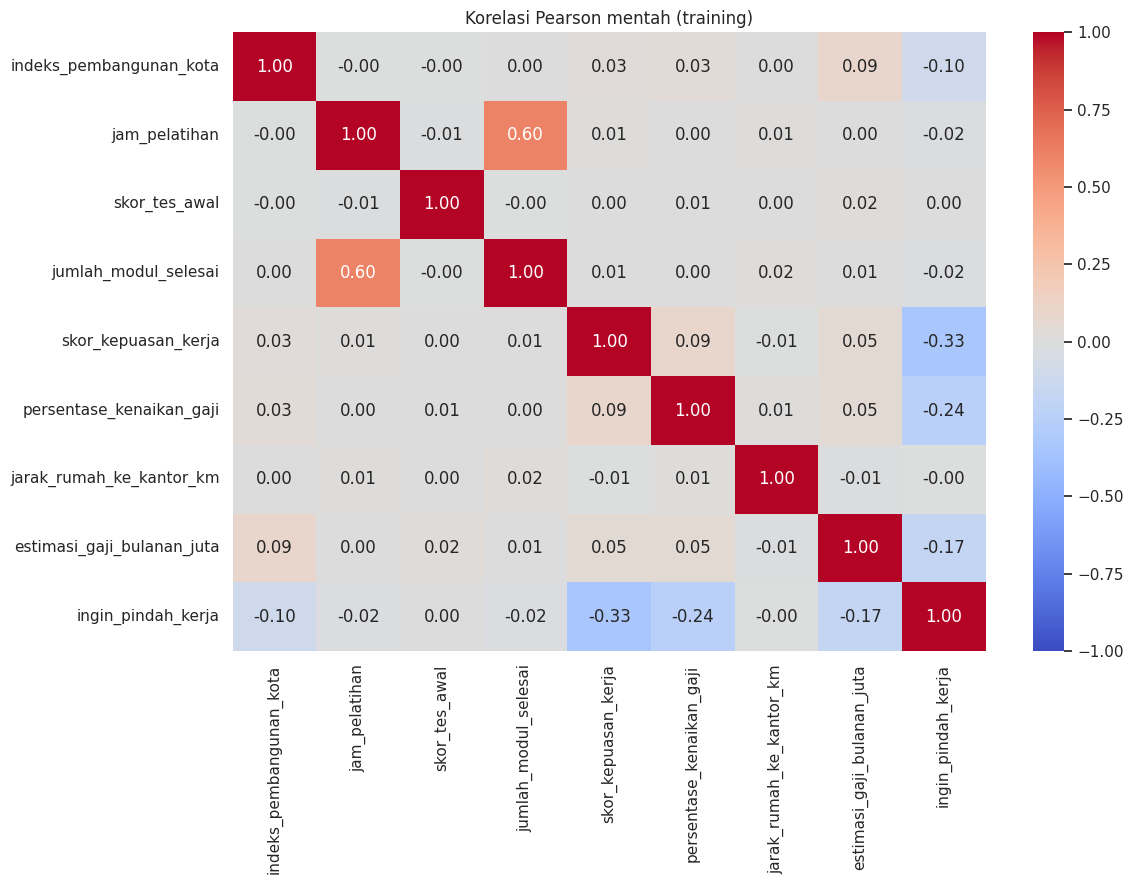

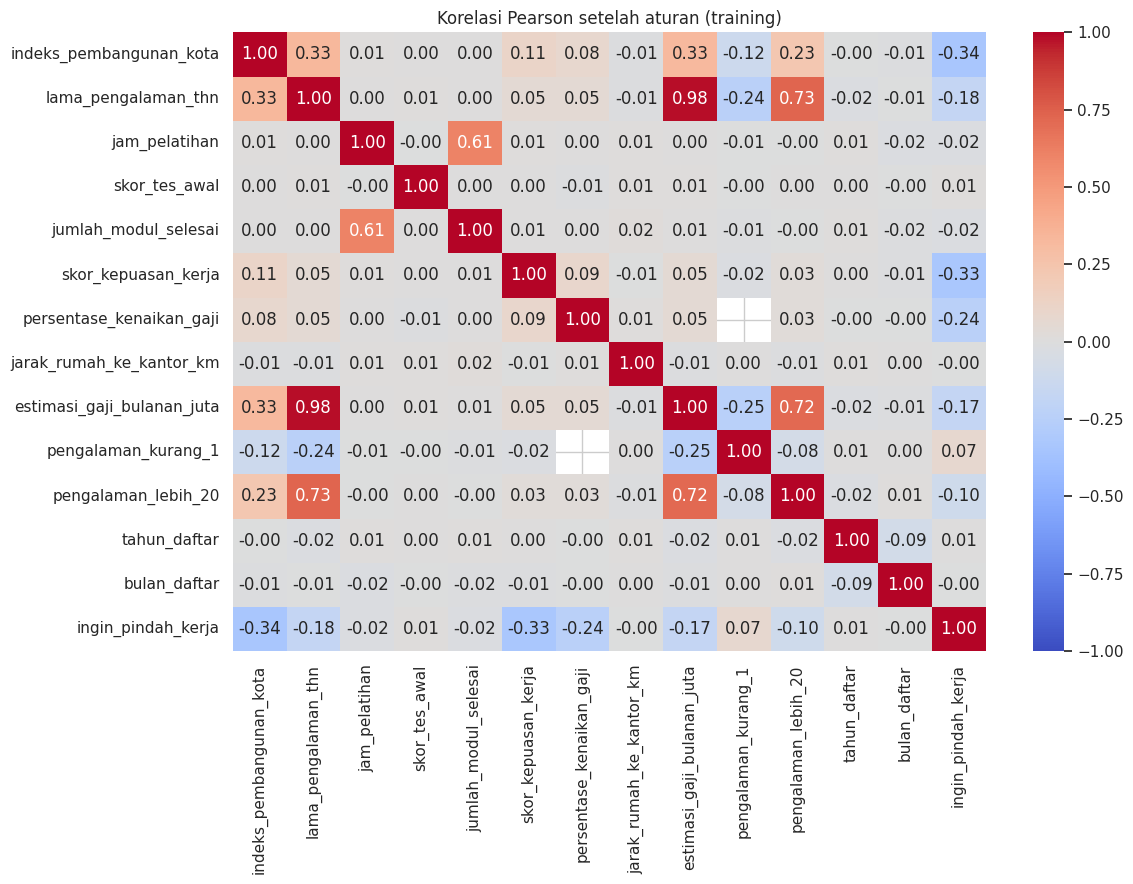

,Pearson mentah,Pearson bersih,Spearman bersih
indeks_pembangunan_kota,-0.103640,-0.342734,-0.280698
skor_kepuasan_kerja,-0.328796,-0.328796,-0.302624
persentase_kenaikan_gaji,-0.237119,-0.237119,-0.216786
lama_pengalaman_thn,NaN,-0.178097,-0.184929
estimasi_gaji_bulanan_juta,-0.173879,-0.173879,-0.179484
pengalaman_lebih_20,NaN,-0.103428,-0.103428
pengalaman_kurang_1,NaN,0.073217,0.073217
jumlah_modul_selesai,-0.022842,-0.022842,-0.014000
jam_pelatihan,-0.017037,-0.016749,-0.014444
skor_tes_awal,0.001380,0.008731,0.009416


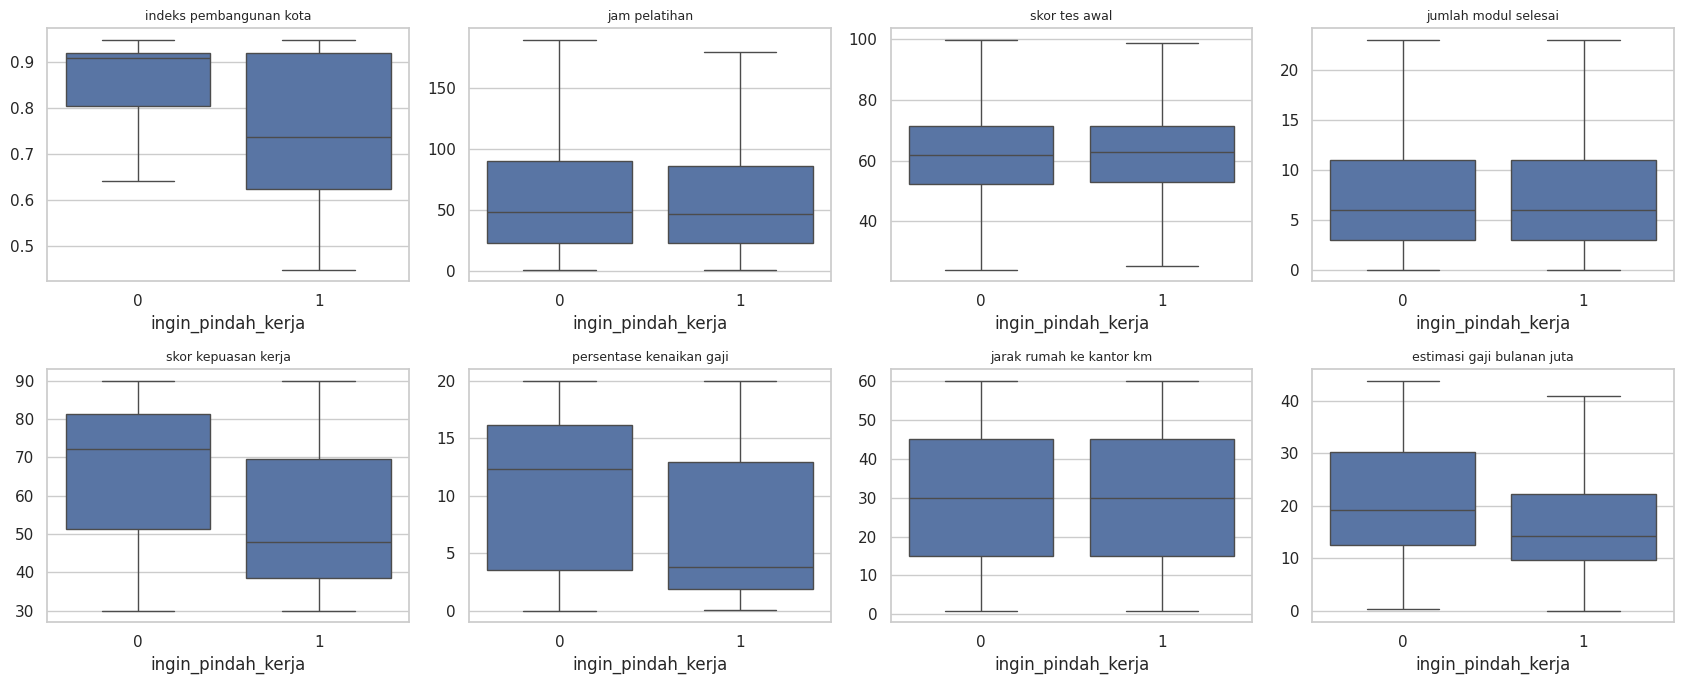

In [9]:
train_eda = X_train.assign(**{TARGET:y_train})
train_clean = clean_features(X_train)
num_clean = train_clean.select_dtypes(include='number')
raw_corr = train_eda.select_dtypes(include='number').corr()
clean_corr = num_clean.assign(**{TARGET:y_train}).corr()
for title,corr in [('Korelasi Pearson mentah (training)',raw_corr),('Korelasi Pearson setelah aturan (training)',clean_corr)]:
    plt.figure(figsize=(12,9))
    sns.heatmap(corr,annot=True,fmt='.2f',cmap='coolwarm',center=0,vmin=-1,vmax=1)
    plt.title(title); plt.tight_layout(); plt.show()
spearman = num_clean.assign(**{TARGET:y_train}).corr(method='spearman')[TARGET].drop(TARGET)
display(pd.DataFrame({'Pearson mentah':raw_corr[TARGET].drop(TARGET),
    'Pearson bersih':clean_corr[TARGET].drop(TARGET),'Spearman bersih':spearman}).sort_values('Pearson bersih',key=abs,ascending=False))
fig, axes = plt.subplots(2,4,figsize=(17,7))
for col,ax in zip(EXPECTED_NUMERIC,axes.flat):
    sns.boxplot(data=train_clean.assign(**{TARGET:y_train}),x=TARGET,y=col,ax=ax,showfliers=False)
    ax.set_title(col.replace('_',' '),fontsize=9); ax.set_ylabel('')
plt.tight_layout(); plt.show()

## 9. Hubungan kategorikal, pola missing, dan kandidat leakage
Gunakan proporsi kelas 1, jumlah dukungan tiap kategori, dan Cramér's V terkoreksi bias. Korelasi/association tinggi bukan bukti kausal atau leakage; waktu koleksi fitur harus diketahui. Kategori langka mudah menghasilkan persentase ekstrem. ID mentah dan kode departemen tidak dinilai dengan Cramér's V karena kardinalitas tinggi.

kode_kota


,jumlah,proporsi_target_1
kode_kota,,
k103,3433,0.2112
k21,2169,0.5911
k16,1210,0.1149
k114,1110,0.1054
k160,651,0.2412
k136,473,0.0973
k67,346,0.1243
k75,248,0.0847
k104,243,0.1029


jenis_kelamin


,jumlah,proporsi_target_1
jenis_kelamin,,
laki-laki,10397,0.2259
__MISSING__,3783,0.3114
perempuan,993,0.2568
lainnya,153,0.2614


pengalaman_relevan


,jumlah,proporsi_target_1
pengalaman_relevan,,
ada,11019,0.2145
tidak ada,4307,0.3385


... (19 outputs left out)

,jumlah,proporsi_target_1
sudah_ajukan_resign,,
belum,10608,0.0463
sudah,4718,0.7060


akses_lamaran_linkedin


,jumlah,proporsi_target_1
akses_lamaran_linkedin,,
tidak pernah,7702,0.0995
sering,3818,0.5464
kadang,3806,0.2549


,fitur,kardinalitas,Cramers V
12,sudah_ajukan_resign,2,0.703850
13,akses_lamaran_linkedin,3,0.421476
0,kode_kota,123,0.388585
6,ukuran_perusahaan,9,0.241541
7,tipe_perusahaan,7,0.217439
3,status_kuliah,4,0.155352
2,pengalaman_relevan,2,0.128558
4,pendidikan,6,0.093795
8,jeda_pindah_kerja_thn,7,0.085604
1,jenis_kelamin,4,0.083038


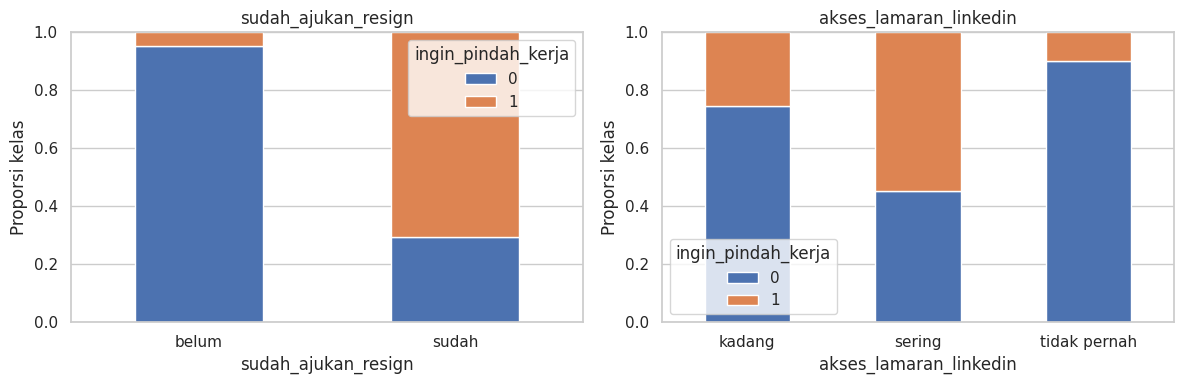

ingin_pindah_kerja,0,1,selisih_abs
ukuran_perusahaan,0.2467,0.5013,0.2546
tipe_perusahaan,0.2683,0.5013,0.2331
jenis_kelamin,0.2264,0.3082,0.0818
persentase_kenaikan_gaji,0.0429,0.0973,0.0544
jurusan,0.1720,0.1287,0.0433
jeda_pindah_kerja_thn,0.0190,0.0319,0.0129
skor_kepuasan_kerja,0.0570,0.0460,0.0110
pendidikan,0.0404,0.0324,0.0080
status_kuliah,0.0189,0.0243,0.0055
estimasi_gaji_bulanan_juta,0.0029,0.0055,0.0026


Kardinalitas ID train: 15326
Kardinalitas kode departemen train: 12463


In [10]:
def corrected_cramers_v(table):
    if min(table.shape)<2: return np.nan
    n = table.to_numpy().sum()
    if n<=1: return np.nan
    chi2 = chi2_contingency(table,correction=False)[0]
    r,k=table.shape
    phi2=max(0,chi2/n-(k-1)*(r-1)/(n-1))
    denom=min(k-1-(k-1)**2/(n-1),r-1-(r-1)**2/(n-1))
    return np.sqrt(phi2/denom) if denom>0 else np.nan

cat_train = train_clean.select_dtypes(exclude='number').copy()
for col in ['sudah_ajukan_resign','akses_lamaran_linkedin']:
    cat_train[col]=normalize_text(X_train[col])
cat_records=[]
for col in cat_train:
    s=cat_train[col].fillna('__MISSING__')
    tab=pd.crosstab(s,y_train)
    cat_records.append({'fitur':col,'kardinalitas':s.nunique(),'Cramers V':corrected_cramers_v(tab)})
    rates=pd.DataFrame({'jumlah':tab.sum(axis=1),'proporsi_target_1':tab[1]/tab.sum(axis=1)})
    print(col)
    display(rates.sort_values('jumlah',ascending=False).head(15).round(4))
display(pd.DataFrame(cat_records).sort_values('Cramers V',ascending=False))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for col,ax in zip(['sudah_ajukan_resign','akses_lamaran_linkedin'],axes):
    pd.crosstab(cat_train[col],y_train,normalize='index').plot.bar(stacked=True,ax=ax,rot=0)
    ax.set(title=col,ylabel='Proporsi kelas',ylim=(0,1))
plt.tight_layout();plt.show()
missing_by_target = train_clean.isna().groupby(y_train).mean().T
missing_by_target['selisih_abs']=(missing_by_target[1]-missing_by_target[0]).abs()
display(missing_by_target.sort_values('selisih_abs',ascending=False).round(4))
print('Kardinalitas ID train:', X_train[ID].nunique())
print('Kardinalitas kode departemen train:', X_train['kode_departemen_asal'].nunique())

## 10. Analisis tanggal dan distribusi kategori utama

,jumlah,proporsi_positif
tanggal_daftar,,
2023-01,702,0.245014
2023-02,612,0.267974
2023-03,683,0.235725
2023-04,686,0.244898
2023-05,657,0.254186
2023-06,670,0.264179
2023-07,677,0.255539
2023-08,713,0.224404
2023-09,685,0.240876


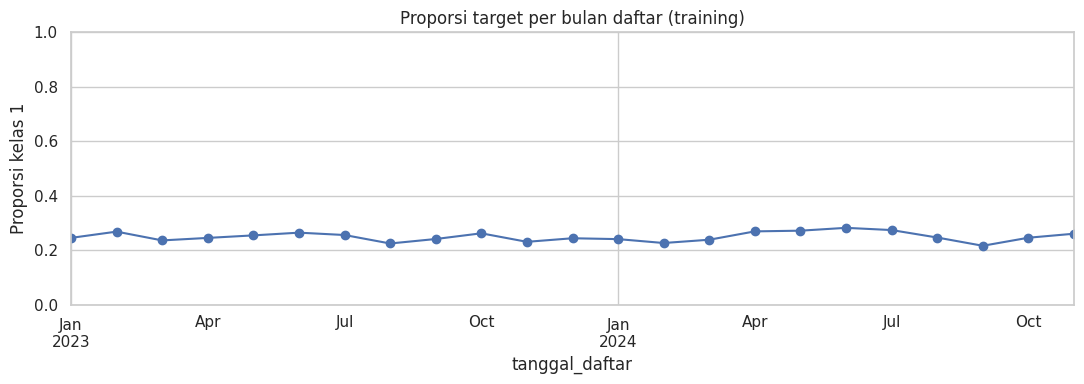

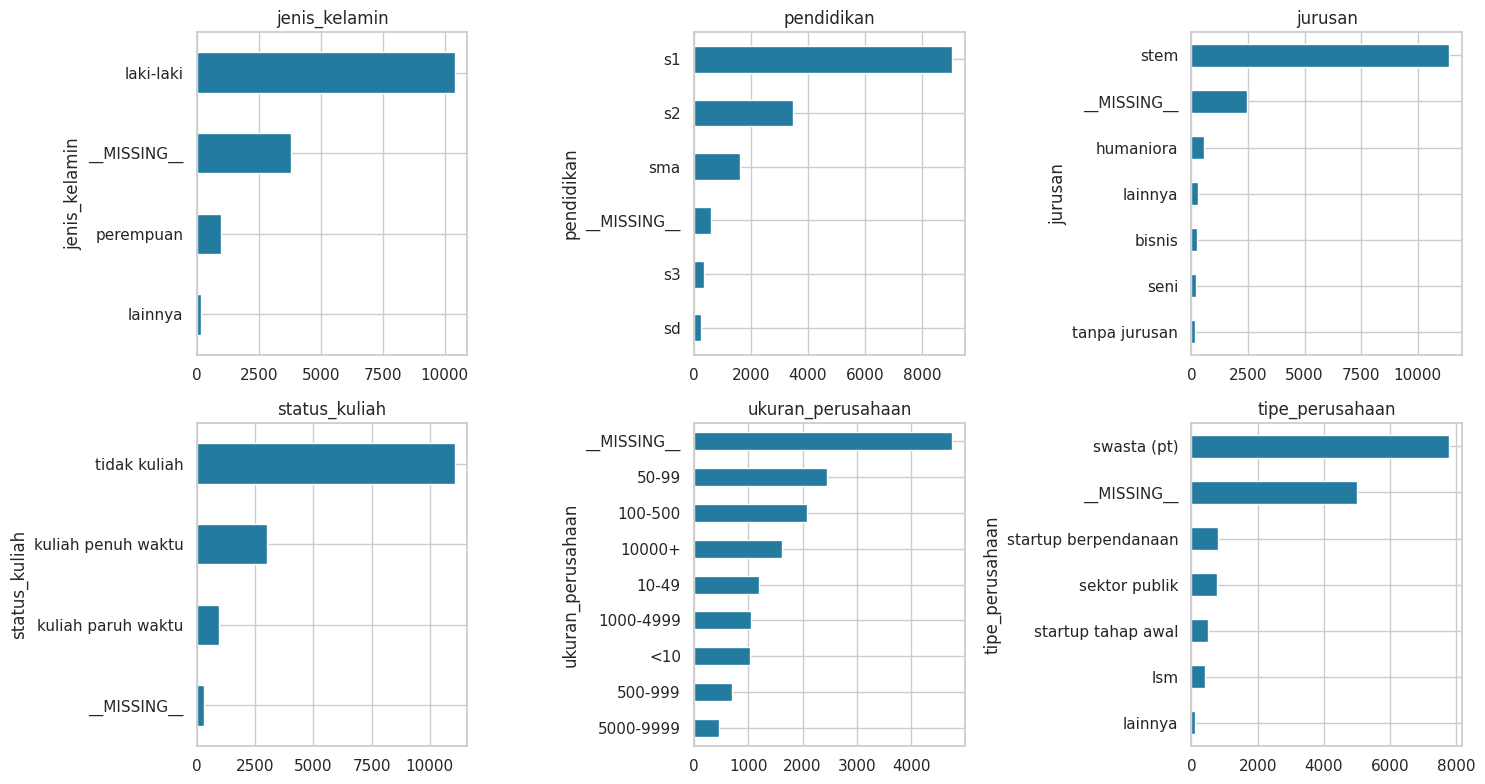

In [11]:
dates_train = pd.to_datetime(X_train['tanggal_daftar'],format='%m/%d/%Y',errors='coerce')
monthly = y_train.groupby(dates_train.dt.to_period('M')).agg(jumlah='size',proporsi_positif='mean')
display(monthly)
ax=monthly['proporsi_positif'].plot(figsize=(11,4),marker='o',ylim=(0,1),title='Proporsi target per bulan daftar (training)')
ax.set_ylabel('Proporsi kelas 1');plt.tight_layout();plt.show()
fig,axes=plt.subplots(2,3,figsize=(15,8))
for col,ax in zip(['jenis_kelamin','pendidikan','jurusan','status_kuliah','ukuran_perusahaan','tipe_perusahaan'],axes.flat):
    c=train_clean[col].fillna('__MISSING__').value_counts().head(12)
    c.sort_values().plot.barh(ax=ax,color='#247BA0')
    ax.set_title(col)
plt.tight_layout();plt.show()

## 11. Kesimpulan EDA dan keputusan preprocessing

- Dataset mentah 25.000 × 27; 26 prediktor (8 numerik, 18 teks) dan target biner. Kelas 1 sekitar 25%; accuracy mayoritas saja tidak cukup.
- Missing efektif mencakup NaN serta placeholder; tidak dilakukan complete-case deletion. Missing numerik diimputasi median train; kategori kosong menjadi kategori sendiri.
- Data berulang tanpa ID adalah temuan utama; deduplikasi dan audit kelompok dilakukan sebelum split. Semua skenario menggunakan **data modeling yang sama**.
- Spasi, kapitalisasi, format pengalaman, format spreadsheet perusahaan dan tanggal ditangani deterministik; nilai domain tidak valid diubah menjadi missing. Clipping jam pelatihan dipelajari dari train, dan nanti diuji pilihan clipping/tanpa clipping.
- Resign dan aktivitas pencarian kerja merupakan proxy berisiko; bukan bukti otomatis leakage. ID dan kode departemen lengkap dihapus dari model aman. Penggunaan fitur progres pelatihan/sertifikasi bergantung waktu ketersediaannya.
- Hubungan Pearson/Spearman dan Cramér's V, missingness per kelas, serta pengamatan per bulan membantu interpretasi tanpa menggunakan label test. Rujuk tabel yang dihasilkan, bukan klaim sebab-akibat.

**Pertanyaan refleksi:** kolom mana yang missing tertinggi? fitur apa yang paling berkorelasi dengan target? mana yang salah secara domain dan mana kandidat outlier? Mengapa ID unik tidak mencegah duplikasi profil? Mengapa F1 dan recall lebih informatif daripada accuracy saja?

### Temuan audit aktual — CSV UAS yang digunakan

| Temuan | Hasil aktual | Tindakan |
|---|---:|---|
| Data mentah | 25.000 baris, 27 kolom | Disimpan utuh untuk EDA |
| Salinan profil+target tanpa ID | 5.842 baris | Deduplikasi sebelum partisi bersama |
| Anggota grup profil berulang | 10.855 baris | Audit berdasarkan fingerprint tanpa ID/target |
| Overlap test lama dengan train | 1.781/5.000 (35,62%) | 0 overlap pada split baru |
| Profil setelah deduplikasi | 19.158 | 15.326 train, 3.832 test |
| Target positif setelah deduplikasi | 4.777 (24,93%) | Stratifikasi, F1/recall dan balancing train-only |
| Missing efektif tipe perusahaan | 8.187 (32,75%) | Kategori missing tersendiri |
| Missing efektif ukuran perusahaan | 7.719 (30,88%) | Kategori missing tersendiri |
| Missing efektif jenis kelamin | 6.158 (24,63%) | Kategori missing tersendiri |
| Missing efektif minimal satu kolom | 16.268 (65,07% data mentah) | Hindari menghapus semua baris kosong |
| Indeks kota di luar 0–1 | 83 | Ubah menjadi missing |
| Jam negatif / >1.000 jam | 38 / 46 | Negatif menjadi missing; nilai positif di-clipping berdasarkan train, bukan dihapus |
| Skor tes di luar 0–100 | 66 | Ubah menjadi missing |
| Format Oct-49 | 1.935 | Normalisasi 10-49 (asumsi kesalahan spreadsheet) |

**Korelasi dan leakage (training setelah deduplikasi):** indeks pembangunan kota berubah dari Pearson −0,104 pada fitur mentah menjadi −0,343 setelah nilai yang melanggar skala 0–1 dibersihkan. Skor kepuasan kerja (−0,329), kenaikan gaji (−0,237), pengalaman (−0,178), dan estimasi gaji (−0,174) juga berkorelasi negatif. Proporsi positif peserta yang sudah mengajukan resign 70,60%, dibanding 4,63% yang belum; akses lamaran sering 54,64%, dibanding tidak pernah 9,95%. Cramér's V masing-masing 0,704 dan 0,421. Keduanya dikeluarkan dalam skenario model prediksi dini. Kategori kode kota juga memiliki asosiasi kuat (0,389), tetapi perlu ditafsirkan dengan hati-hati dan bukan hubungan kausal.

Missing ukuran perusahaan pada kelas 1 (50,13%) lebih tinggi dibanding kelas 0 (24,67%); pola serupa pada tipe perusahaan. Informasi missing ini mungkin prediktif, tetapi asal dan waktu missing tetap perlu dikonfirmasi.

# Tahap 2 — Direct Modeling
## 1. Konversi minimal dan tiga model baseline
Direct tetap menggunakan semua 26 fitur mentah sesuai skenario semula, termasuk calon proxy dan ID; tidak ada cleaning fitur, scaling, resampling, atau tuning di tahap ini. Perbaikan deduplikasi/split berlaku untuk **seluruh skenario** demi evaluasi adil. Kode ordinal tidak bermakna jarak untuk KNN, dan fitur ID berpotensi memicu model mempelajari pola semu. Baseline ini bukan model deployment.

In [12]:
numeric_cols = X_train.select_dtypes(include='number').columns.tolist()
categorical_cols = X_train.select_dtypes(exclude='number').columns.tolist()
minimal_converter = ColumnTransformer([
    ('numeric',SimpleImputer(strategy='median',keep_empty_features=True),numeric_cols),
    ('categorical',Pipeline([
        ('impute',SimpleImputer(strategy='constant',fill_value='__MISSING__',keep_empty_features=True)),
        ('encode',OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1))
    ]),categorical_cols)])
print('Fitur:',X_train.shape[1],'| numerik:',len(numeric_cols),'| kategorikal:',len(categorical_cols))
display(X_train.dtypes.to_frame('tipe_data'))

def make_models():
    return {
        'Decision Tree':DecisionTreeClassifier(random_state=RANDOM_STATE),
        'Random Forest':RandomForestClassifier(random_state=RANDOM_STATE,n_jobs=N_JOBS),
        'Voting Classifier':VotingClassifier(estimators=[
            ('dt',DecisionTreeClassifier(random_state=RANDOM_STATE)),
            ('knn',KNeighborsClassifier(n_jobs=N_JOBS)),
            ('gnb',GaussianNB())],voting='hard')
    }
models=make_models()

Fitur: 26 | numerik: 8 | kategorikal: 18


,tipe_data
id_peserta,object
kode_kota,object
indeks_pembangunan_kota,float64
jenis_kelamin,object
pengalaman_relevan,object
status_kuliah,object
pendidikan,object
jurusan,object
lama_pengalaman_thn,object
ukuran_perusahaan,object


| Model | Prinsip |
|---|---|
| Decision Tree | Pohon keputusan, konvensional |
| Random Forest | Ensemble bagging beberapa decision tree |
| Voting Classifier | Hard voting dari Decision Tree, KNN dan Gaussian Naive Bayes |

Masing-masing estimator di-clone untuk menghindari state bersama. Skor test akan dihitung dengan fungsi evaluasi yang sama. F1 positif ialah rata-rata harmonik precision (ketepatan prediksi positif) dan recall (cakupan positif). Balanced accuracy mempertimbangkan recall kedua kelas.

In [13]:
METRICS=['Accuracy','Precision','Recall','F1-score']
def evaluate_models(fitted, scenario, X_eval, y_eval):
    rows,preds,scores={}, {}, {}
    for name,model in fitted.items():
        pred=model.predict(X_eval)
        assert len(pred)==len(y_eval)
        preds[name]=pred
        tn,fp,fn,tp=confusion_matrix(y_eval,pred,labels=[0,1]).ravel()
        row={'Model':name,'Skenario':scenario,'Accuracy':accuracy_score(y_eval,pred),
            'Precision':precision_score(y_eval,pred,pos_label=1,zero_division=0),
            'Recall':recall_score(y_eval,pred,pos_label=1,zero_division=0),
            'F1-score':f1_score(y_eval,pred,pos_label=1,zero_division=0),
            'Balanced Accuracy':balanced_accuracy_score(y_eval,pred),
            'TN':tn,'FP':fp,'FN':fn,'TP':tp}
        # Hard voting tidak menyediakan probabilitas; jangan memalsukan AUC dari label keras.
        if hasattr(model,'predict_proba'):
            score=model.predict_proba(X_eval)[:,list(model.classes_).index(1)]
            scores[name]=score
            row.update({'ROC-AUC':roc_auc_score(y_eval,score),'Average Precision':average_precision_score(y_eval,score)})
        else:
            row.update({'ROC-AUC':np.nan,'Average Precision':np.nan})
        rows[name]=row
        print(''); print(scenario,'—',name)
        print(classification_report(y_eval,pred,labels=[0,1],target_names=['Tidak ingin pindah','Ingin pindah'],zero_division=0))
    return pd.DataFrame(rows.values()),preds,scores

def plot_evaluation(results,preds,y_eval,title):
    display(results.round(4))
    fig,axes=plt.subplots(1,len(preds),figsize=(5*len(preds),4),squeeze=False)
    for ax,(name,pred) in zip(axes.flat,preds.items()):
        cm=confusion_matrix(y_eval,pred,labels=[0,1])
        ConfusionMatrixDisplay(cm,display_labels=[0,1]).plot(ax=ax,cmap='Blues',colorbar=False)
        ax.set_title(name)
        print(name,dict(zip(['TN','FP','FN','TP'],cm.ravel())))
    plt.suptitle(title);plt.tight_layout();plt.show()
    ax=results.set_index('Model')[METRICS].plot.bar(figsize=(11,5),rot=0)
    ax.set(title=title,ylabel='Skor',ylim=(0,1.12))
    for container in ax.containers:ax.bar_label(container,fmt='%.3f',fontsize=8,padding=2)
    plt.tight_layout();plt.show()

def fit_models(builder):
    fitted={}
    for name,est in make_models().items():
        start=perf_counter()
        fitted[name]=builder(clone(est)).fit(X_train,y_train)
        print(name,'selesai dalam',round(perf_counter()-start,2),'detik')
    return fitted

# Dummy untuk melihat keterbatasan accuracy kelas mayoritas, bukan bagian sembilan eksperimen.
dummy=DummyClassifier(strategy='most_frequent').fit(X_train,y_train)
dummy_pred=dummy.predict(X_test)
print('Dummy accuracy:',accuracy_score(y_test,dummy_pred),'| F1:',f1_score(y_test,dummy_pred,zero_division=0))

Dummy accuracy: 0.7507828810020877 | F1: 0.0


## 2. Training, evaluasi, classification report, dan confusion matrix

Decision Tree selesai dalam 0.51 detik
Random Forest selesai dalam 3.94 detik
Voting Classifier selesai dalam 0.8 detik

Direct — Decision Tree
                    precision    recall  f1-score   support

Tidak ingin pindah       0.89      0.85      0.87      2877
      Ingin pindah       0.60      0.69      0.64       955

          accuracy                           0.81      3832
         macro avg       0.75      0.77      0.76      3832
      weighted avg       0.82      0.81      0.81      3832


Direct — Random Forest
                    precision    recall  f1-score   support

Tidak ingin pindah       0.94      0.96      0.95      2877
      Ingin pindah       0.87      0.80      0.83       955

          accuracy                           0.92      3832
         macro avg       0.90      0.88      0.89      3832
      weighted avg       0.92      0.92      0.92      3832


Direct — Voting Classifier
                    precision    recall  f1-score   support

Tidak ingin pinda

,Model,Skenario,Accuracy,Precision,Recall,F1-score,Balanced Accuracy,TN,FP,FN,TP,ROC-AUC,Average Precision
0,Decision Tree,Direct,0.8090,0.6026,0.6859,0.6415,0.7679,2445,432,300,655,0.7679,0.4916
1,Random Forest,Direct,0.9207,0.8720,0.7990,0.8339,0.8800,2765,112,192,763,0.9586,0.9074
2,Voting Classifier,Direct,0.8760,0.8279,0.6346,0.7184,0.7954,2751,126,349,606,NaN,NaN


Decision Tree {'TN': np.int64(2445), 'FP': np.int64(432), 'FN': np.int64(300), 'TP': np.int64(655)}
Random Forest {'TN': np.int64(2765), 'FP': np.int64(112), 'FN': np.int64(192), 'TP': np.int64(763)}
Voting Classifier {'TN': np.int64(2751), 'FP': np.int64(126), 'FN': np.int64(349), 'TP': np.int64(606)}


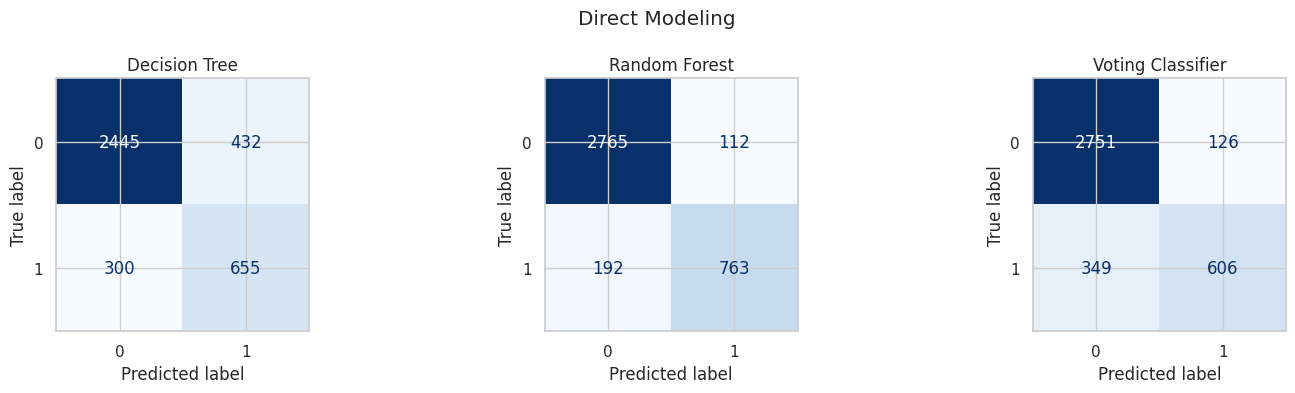

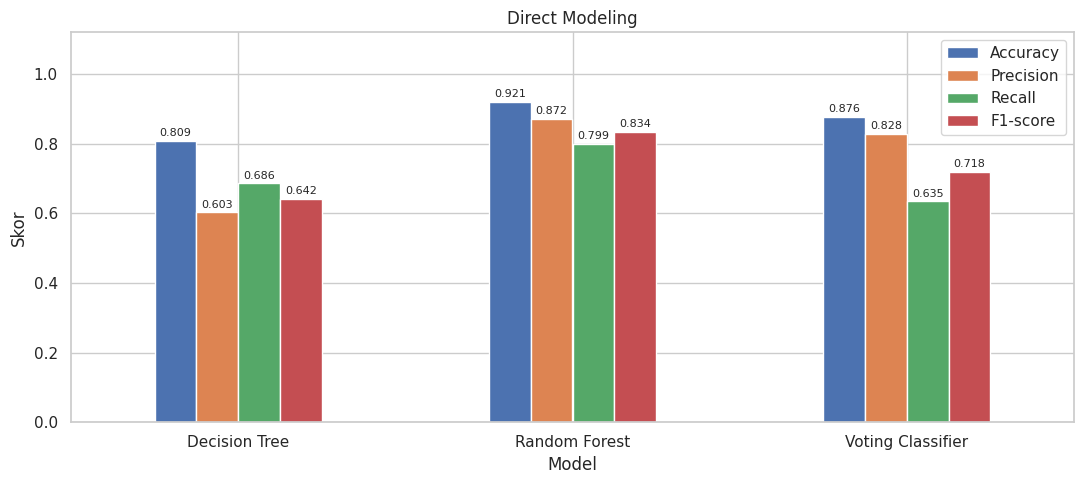

Baseline F1 tertinggi (deskriptif):


,Model,Skenario,Accuracy,Precision,Recall,F1-score,Balanced Accuracy,TN,FP,FN,TP,ROC-AUC,Average Precision
1,Random Forest,Direct,0.920668,0.872,0.798953,0.83388,0.880012,2765,112,192,763,0.958609,0.907365


In [14]:
direct_models=fit_models(lambda est:Pipeline([('conversion',clone(minimal_converter)),('model',est)]))
results_direct,pred_direct,score_direct=evaluate_models(direct_models,'Direct',X_test,y_test)
plot_evaluation(results_direct,pred_direct,y_test,'Direct Modeling')
results_direct.to_csv(OUTPUT_DIR/'hasil_direct_modeling.csv',index=False)
print('Baseline F1 tertinggi (deskriptif):')
display(results_direct.nlargest(1,'F1-score'))

## 3. Kesimpulan Direct Modeling
Interpretasi hasil: bandingkan F1, recall, TN/FP/FN/TP; FN berarti peserta ingin pindah tetapi tidak terdeteksi. Skor tinggi direct mungkin dipengaruhi proxy seperti resign, bukan bukti bahwa model aman. Jumlah data train/test ditampilkan di Tahap 1. Jelaskan perbedaan tiga model, kelemahan ordinal encoding, dan mengapa preprocessing diperlukan. Jangan memilih parameter atau deployment berdasarkan skor test direct.

# Tahap 3 — Modeling dengan Preprocessing
## 1. Seleksi fitur dan pemeriksaan sebelum/sesudah
Pembersihan mengacu pada fungsi Tahap 1; pipeline menerima data mentah dan mentransformasi secara konsisten. Kolom target tidak pernah diikutsertakan. Semua metode yang belajar statistik di-fit pada training dan diulang per fold.

In [15]:
print('Fitur dikeluarkan:',DROP_FEATURES)
for col in ['sudah_ajukan_resign','akses_lamaran_linkedin']:
    display(pd.crosstab(X_train[col],y_train,normalize='index').round(4))
X_train_clean=clean_features(X_train)
print('Fitur mentah:',X_train.shape[1],'| fitur setelah aturan:',X_train_clean.shape[1])
display(X_train_clean.head())
before_after=pd.DataFrame({'missing_asli':X_train.isna().sum(),
    'missing_setelah_aturan':X_train_clean.isna().sum(),
    'unik_asli':X_train.nunique(),'unik_setelah_aturan':X_train_clean.nunique()})
display(before_after)
assert X_train_clean.index.equals(X_train.index)
assert TARGET not in X_train_clean and not set(DROP_FEATURES)&set(X_train_clean)
assert len(X_train_clean)==len(X_train)
assert not (X_train_clean['jam_pelatihan'].dropna()<0).any()
assert X_train_clean['indeks_pembangunan_kota'].dropna().between(0,1).all()
assert X_train_clean['skor_tes_awal'].dropna().between(0,100).all()
assert not X_train_clean['ukuran_perusahaan'].eq('oct-49').any()
before_after.to_csv(OUTPUT_DIR/'audit_preprocessing.csv')

Fitur dikeluarkan: ['id_peserta', 'kode_departemen_asal', 'sudah_ajukan_resign', 'akses_lamaran_linkedin']


ingin_pindah_kerja,0,1
sudah_ajukan_resign,,
Belum,0.9537,0.0463
Sudah,0.2940,0.7060


ingin_pindah_kerja,0,1
akses_lamaran_linkedin,,
Kadang,0.7451,0.2549
Sering,0.4536,0.5464
Tidak Pernah,0.9005,0.0995


Fitur mentah: 26 | fitur setelah aturan: 25


,kode_kota,indeks_pembangunan_kota,jenis_kelamin,pengalaman_relevan,status_kuliah,pendidikan,jurusan,lama_pengalaman_thn,ukuran_perusahaan,tipe_perusahaan,jeda_pindah_kerja_thn,jam_pelatihan,sumber_info,skor_tes_awal,jumlah_modul_selesai,skor_kepuasan_kerja,persentase_kenaikan_gaji,jarak_rumah_ke_kantor_km,kegiatan_ekstrakurikuler,estimasi_gaji_bulanan_juta,sertifikasi_it,pengalaman_kurang_1,pengalaman_lebih_20,tahun_daftar,bulan_daftar
18295,k103,0.920,NaN,tidak ada,tidak kuliah,s2,NaN,21.0,10000+,swasta (pt),>4,91.0,instagram,NaN,11,31.0,3.66,3.0,relawan,35.35,tidak ada,0.0,1.0,2023.0,5.0
18089,k21,0.624,laki-laki,ada,tidak kuliah,s1,stem,3.0,50-99,swasta (pt),>4,70.0,instagram,77.5,9,69.7,13.96,37.0,tidak ada,9.92,data science bootcamp,0.0,0.0,2024.0,2.0
13669,k67,0.855,laki-laki,ada,tidak kuliah,s2,stem,12.0,50-99,NaN,1,110.0,instagram,52.1,13,89.6,15.88,58.0,seni,20.76,tidak ada,0.0,0.0,2023.0,7.0
13619,k41,0.827,laki-laki,ada,kuliah penuh waktu,s1,stem,21.0,100-500,swasta (pt),>4,72.0,linkedin,NaN,10,76.7,17.75,31.0,tidak ada,31.01,tidak ada,0.0,1.0,2024.0,6.0
16254,k16,0.910,perempuan,tidak ada,kuliah penuh waktu,s1,stem,3.0,NaN,NaN,belum pernah,34.0,linkedin,36.1,4,86.0,3.35,56.0,olahraga,9.73,graph analytics cert,0.0,0.0,2024.0,4.0


,missing_asli,missing_setelah_aturan,unik_asli,unik_setelah_aturan
akses_lamaran_linkedin,0.0,NaN,3.0,NaN
bulan_daftar,NaN,0.0,NaN,12.0
estimasi_gaji_bulanan_juta,54.0,54.0,3685.0,3685.0
id_peserta,0.0,NaN,15326.0,NaN
indeks_pembangunan_kota,309.0,353.0,114.0,93.0
jam_pelatihan,296.0,322.0,311.0,285.0
jarak_rumah_ke_kantor_km,779.0,779.0,60.0,60.0
jeda_pindah_kerja_thn,341.0,341.0,6.0,6.0
jenis_kelamin,3651.0,3783.0,6.0,3.0
jumlah_modul_selesai,0.0,0.0,45.0,45.0


## 2. Pipeline imputasi, clipping, encoding, dan scaling
- Numerik: median, StandardScaler. Indikator missing terpisah mempertahankan informasi bahwa nilai sebelumnya kosong/tidak valid (tanpa menguatkan indikator langka oleh scaling).
- Jam pelatihan: quantile clipping 99% positif, kemudian imputasi dan scaling. Kuantil belajar dari training; alternatif tanpa clipping diuji pada tuning.
- Kategori: missing khusus, one-hot encoding dengan kategori jarang (<20 observasi train) digabung; kategori baru tidak menimbulkan error. Dense output diperlukan GaussianNB. ID/kode departemen sudah dibuang sehingga dimensi terkendali.
- StandardScaler membantu jarak KNN; untuk pohon scaling umumnya tidak diperlukan tetapi preprocessing identik antar model mempermudah perbandingan.

In [16]:
class UpperQuantileClipper(TransformerMixin,BaseEstimator):
    def __init__(self,quantile=.99):self.quantile=quantile
    def fit(self,X,y=None):
        arr=np.asarray(X,dtype=float)
        self.n_features_in_=arr.shape[1]
        self.upper_=np.array([np.quantile(c[np.isfinite(c)],self.quantile)
                              if self.quantile is not None and np.isfinite(c).any() else np.inf
                              for c in arr.T])
        return self
    def transform(self,X):
        check_is_fitted(self,'upper_')
        return np.minimum(np.asarray(X,dtype=float),self.upper_)
    def get_feature_names_out(self,input_features=None):
        return np.asarray(input_features if input_features is not None else
                         [f'x{i}' for i in range(self.n_features_in_)],dtype=object)

def other_numeric(frame):
    return [c for c in frame.select_dtypes(include='number') if c!='jam_pelatihan']
def categorical_columns(frame):
    return frame.select_dtypes(exclude='number').columns.tolist()
def all_numeric(frame):
    return frame.select_dtypes(include='number').columns.tolist()

preprocessor=ColumnTransformer([
    ('hours',Pipeline([('clip',UpperQuantileClipper()),
        ('impute',SimpleImputer(strategy='median',keep_empty_features=True)),('scale',StandardScaler())]),['jam_pelatihan']),
    ('numeric',Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),
        ('scale',StandardScaler())]),other_numeric),
    ('missing_flags',MissingIndicator(features='missing-only',error_on_new=False),all_numeric),
    ('categorical',Pipeline([('impute',SimpleImputer(strategy='constant',fill_value='__MISSING__',keep_empty_features=True)),
        ('encode',OneHotEncoder(handle_unknown='infrequent_if_exist',min_frequency=20,sparse_output=False))]),categorical_columns)
],remainder='drop')

preview=clone(preprocessor)
X_train_encoded=preview.fit_transform(X_train_clean)
X_test_encoded=preview.transform(clean_features(X_test))
print('Batas jam training:',preview.named_transformers_['hours'].named_steps['clip'].upper_)
print('Train encoded:',X_train_encoded.shape,'| Test encoded:',X_test_encoded.shape)
print('Nilai nonfinite train/test:', (~np.isfinite(X_train_encoded)).sum(),(~np.isfinite(X_test_encoded)).sum())
assert np.isfinite(X_train_encoded).all() and np.isfinite(X_test_encoded).all()
assert X_train_encoded.shape[1]==X_test_encoded.shape[1]
assert len(X_test_encoded)==len(X_test)
feature_names=preview.get_feature_names_out()
display(pd.DataFrame({'fitur_encoded':feature_names}).head(30))
print('Jumlah kategori per fitur, sebelum rare grouping (training):')
encoder=preview.named_transformers_['categorical'].named_steps['encode']
display(pd.Series([len(c) for c in encoder.categories_],index=categorical_columns(X_train_clean)))

# Uji regresi: kategori yang belum pernah terlihat tetap bisa ditransformasi.
probe=X_train.iloc[[0]].copy()
probe['kode_kota']='KOTA-BARU-TIDAK-DIKENAL'
probe['jam_pelatihan']=-99
assert np.isfinite(preview.transform(clean_features(probe))).all()
print('PASS: kategori baru, anomali, dimensi dan finite values.')

Batas jam training: [314.]
Train encoded: (15326, 171) | Test encoded: (3832, 171)
Nilai nonfinite train/test: 0 0


,fitur_encoded
0,hours__jam_pelatihan
1,numeric__indeks_pembangunan_kota
2,numeric__lama_pengalaman_thn
3,numeric__skor_tes_awal
4,numeric__jumlah_modul_selesai
5,numeric__skor_kepuasan_kerja
6,numeric__persentase_kenaikan_gaji
7,numeric__jarak_rumah_ke_kantor_km
8,numeric__estimasi_gaji_bulanan_juta
9,numeric__pengalaman_kurang_1


Jumlah kategori per fitur, sebelum rare grouping (training):


,0
kode_kota,123
jenis_kelamin,4
pengalaman_relevan,2
status_kuliah,4
pendidikan,6
jurusan,7
ukuran_perusahaan,9
tipe_perusahaan,7
jeda_pindah_kerja_thn,7
sumber_info,6


PASS: kategori baru, anomali, dimensi dan finite values.


## 3. Balancing kelas pada training saja
Random oversampling asli dipertahankan: rasio 1.0 menyeimbangkan kelas minoritas dengan mayoritas. Wrapper sekarang mendukung rasio parsial atau tanpa oversampling sehingga dapat diuji via CV. Tidak ada resampling sebelum pembagian holdout atau fold. Test set tidak berubah. Probabilitas DT/RF tersedia, hard voting tidak; probabilitas setelah oversampling belum tentu terkalibrasi.

In [17]:
from sklearn.utils.metaestimators import available_if
def can_predict_proba(wrapper):
    return hasattr(getattr(wrapper,'estimator_',wrapper.estimator),'predict_proba')

class BalancedClassifier(ClassifierMixin,BaseEstimator):
    def __init__(self,estimator,random_state=42,ratio=1.0,threshold=None):
        self.estimator=estimator
        self.random_state=random_state
        self.ratio=ratio
        self.threshold=threshold
    def fit(self,X,y):
        X,y=np.asarray(X),np.asarray(y)
        rng=np.random.default_rng(self.random_state)
        labels,counts=np.unique(y,return_counts=True)
        if self.ratio is not None and not 0<self.ratio<=1:
            raise ValueError('ratio harus (0,1] atau None')
        target_count=int(np.ceil(counts.max()*self.ratio)) if self.ratio is not None else 0
        indices=[]
        for label in labels:
            idx=np.flatnonzero(y==label)
            extra=rng.choice(idx,size=max(0,target_count-len(idx)),replace=True)
            indices.append(np.concatenate([idx,extra]))
        indices=rng.permutation(np.concatenate(indices))
        self.estimator_=clone(self.estimator).fit(X[indices],y[indices])
        self.classes_=self.estimator_.classes_
        self.resampled_counts_={int(k):int(v) for k,v in zip(*np.unique(y[indices],return_counts=True))}
        self.n_features_in_=X.shape[1]
        return self
    def predict(self,X):
        check_is_fitted(self,'estimator_')
        if self.threshold is not None and hasattr(self.estimator_, 'predict_proba'):
            return (self.predict_proba(X)[:,list(self.classes_).index(1)] >= self.threshold).astype(int)
        return self.estimator_.predict(X)
    @available_if(can_predict_proba)
    def predict_proba(self,X):
        check_is_fitted(self,'estimator_')
        return self.estimator_.predict_proba(X)

def safe_pipeline(est):
    return Pipeline([('clean',FunctionTransformer(clean_features,validate=False)),
                     ('preprocess',clone(preprocessor)),
                     ('model',BalancedClassifier(clone(est),random_state=RANDOM_STATE))])

print('Distribusi train sebelum balancing:',y_train.value_counts().sort_index().to_dict())
preprocessing_models=fit_models(safe_pipeline)
for name,pipeline in preprocessing_models.items():
    print(name,'distribusi resampling:',pipeline.named_steps['model'].resampled_counts_)
    assert len(set(pipeline.named_steps['model'].resampled_counts_.values()))==1
assert len(y_test)==len(test_idx)
# Menghindari retensi matriks preview yang tidak diperlukan saat tuning.
del X_train_encoded,X_test_encoded

Distribusi train sebelum balancing: {0: 11504, 1: 3822}
Decision Tree selesai dalam 1.53 detik
Random Forest selesai dalam 5.06 detik
Voting Classifier selesai dalam 1.63 detik
Decision Tree distribusi resampling: {0: 11504, 1: 11504}
Random Forest distribusi resampling: {0: 11504, 1: 11504}
Voting Classifier distribusi resampling: {0: 11504, 1: 11504}


## 4. Training dan evaluasi tiga model setelah preprocessing


Preprocessing — Decision Tree
                    precision    recall  f1-score   support

Tidak ingin pindah       0.85      0.84      0.84      2877
      Ingin pindah       0.53      0.55      0.54       955

          accuracy                           0.77      3832
         macro avg       0.69      0.69      0.69      3832
      weighted avg       0.77      0.77      0.77      3832


Preprocessing — Random Forest
                    precision    recall  f1-score   support

Tidak ingin pindah       0.87      0.91      0.89      2877
      Ingin pindah       0.68      0.60      0.64       955

          accuracy                           0.83      3832
         macro avg       0.78      0.76      0.77      3832
      weighted avg       0.83      0.83      0.83      3832


Preprocessing — Voting Classifier
                    precision    recall  f1-score   support

Tidak ingin pindah       0.90      0.76      0.82      2877
      Ingin pindah       0.51      0.74      0.60       

,Model,Skenario,Accuracy,Precision,Recall,F1-score,Balanced Accuracy,TN,FP,FN,TP,ROC-AUC,Average Precision
0,Decision Tree,Preprocessing,0.7664,0.5305,0.5455,0.5379,0.6927,2416,461,434,521,0.6927,0.4027
1,Random Forest,Preprocessing,0.8319,0.6849,0.6031,0.6414,0.7555,2612,265,379,576,0.8607,0.6811
2,Voting Classifier,Preprocessing,0.7557,0.5068,0.7393,0.6014,0.7502,2190,687,249,706,NaN,NaN


Decision Tree {'TN': np.int64(2416), 'FP': np.int64(461), 'FN': np.int64(434), 'TP': np.int64(521)}
Random Forest {'TN': np.int64(2612), 'FP': np.int64(265), 'FN': np.int64(379), 'TP': np.int64(576)}
Voting Classifier {'TN': np.int64(2190), 'FP': np.int64(687), 'FN': np.int64(249), 'TP': np.int64(706)}


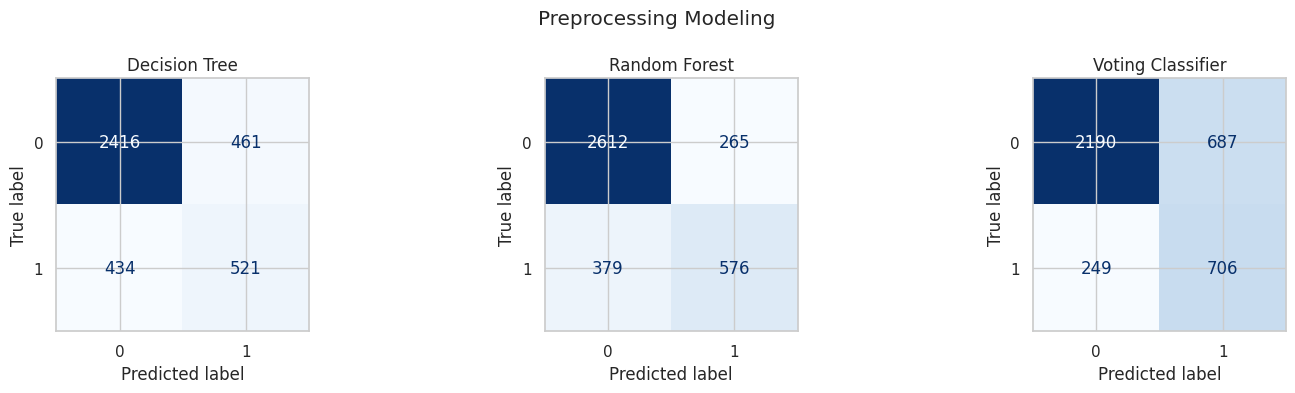

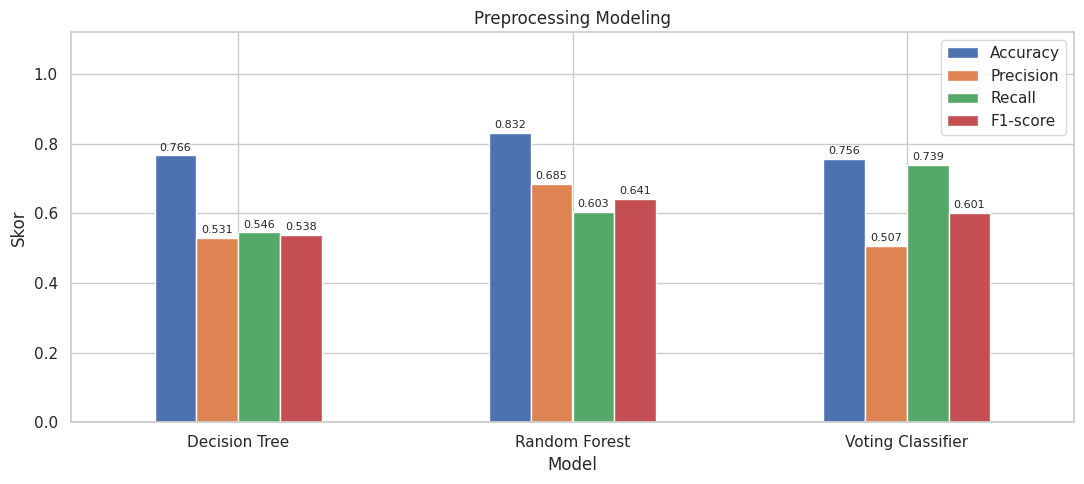

,Model,Skenario,Accuracy,Precision,Recall,F1-score,Balanced Accuracy,TN,FP,FN,TP,ROC-AUC,Average Precision
0,Decision Tree,Direct,0.8090,0.6026,0.6859,0.6415,0.7679,2445,432,300,655,0.7679,0.4916
1,Random Forest,Direct,0.9207,0.8720,0.7990,0.8339,0.8800,2765,112,192,763,0.9586,0.9074
2,Voting Classifier,Direct,0.8760,0.8279,0.6346,0.7184,0.7954,2751,126,349,606,NaN,NaN
3,Decision Tree,Preprocessing,0.7664,0.5305,0.5455,0.5379,0.6927,2416,461,434,521,0.6927,0.4027
4,Random Forest,Preprocessing,0.8319,0.6849,0.6031,0.6414,0.7555,2612,265,379,576,0.8607,0.6811
5,Voting Classifier,Preprocessing,0.7557,0.5068,0.7393,0.6014,0.7502,2190,687,249,706,NaN,NaN


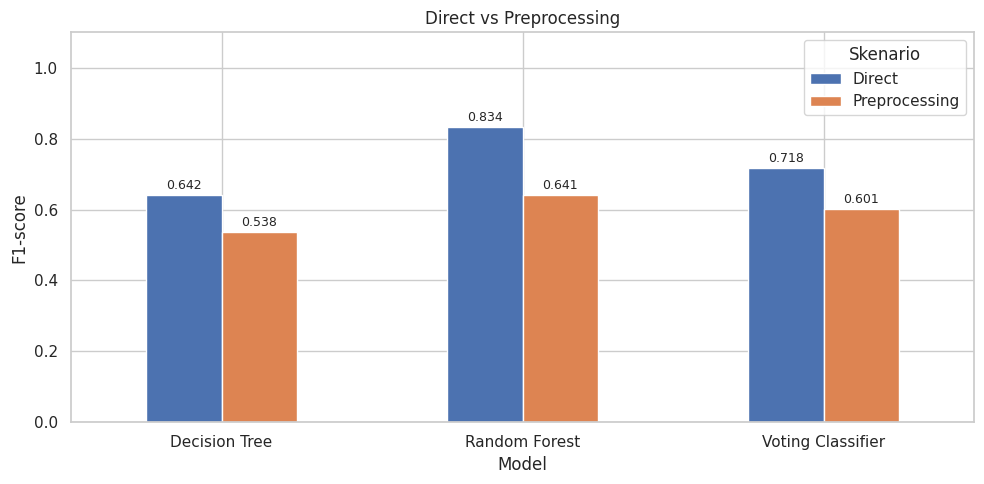

In [18]:
results_preprocessing,pred_preprocessing,score_preprocessing=evaluate_models(preprocessing_models,'Preprocessing',X_test,y_test)
plot_evaluation(results_preprocessing,pred_preprocessing,y_test,'Preprocessing Modeling')
results_preprocessing.to_csv(OUTPUT_DIR/'hasil_preprocessing_modeling.csv',index=False)
comparison_stage3=pd.concat([results_direct,results_preprocessing],ignore_index=True)
display(comparison_stage3.round(4))
ax=comparison_stage3.pivot(index='Model',columns='Skenario',values='F1-score').plot.bar(figsize=(10,5),rot=0)
ax.set(title='Direct vs Preprocessing',ylabel='F1-score',ylim=(0,1.1))
for container in ax.containers:ax.bar_label(container,fmt='%.3f',fontsize=9,padding=2)
plt.tight_layout();plt.show()

## 5. Kesimpulan Preprocessing
Bandingkan hasil sebelum/sesudah; penurunan skor setelah menghapus proxy dapat berarti evaluasi lebih realistis. Perubahan preprocessing tidak dapat dikaitkan pada satu teknik karena beberapa teknik berubah bersamaan. Jelaskan missing, duplikasi, format, outlier, fitur yang dibuang, hasil encoding dan oversampling; bandingkan F1 maupun recall. Jangan menjadikan test set sebagai dasar memilih konfigurasi tuning.

# Tahap 4 — Hyperparameter Tuning
## 1. Ruang pencarian terkontrol
GridSearchCV menguji regularisasi dan strategi balancing pada parameter yang sama (tanpa sampling, ROS, dan class_weight pada DT/RF). Voting menguji hard dan soft pada anggota model yang tetap sama. Tidak ada algoritma tambahan. F1 kelas 1 menjadi kriteria utama; test tidak digunakan untuk memilih parameter atau threshold.


In [19]:
prefix='model__estimator__'
def grid(candidates):
    return [{(key if key.startswith(('model__','preprocess__')) else prefix+key):[value]
             for key,value in candidate.items()} for candidate in candidates]

# Konfigurasi pertama selalu baseline preprocessing agar delta CV dapat dihitung.
strategies=[{'model__ratio':1.0,'class_weight':None},
            {'model__ratio':None,'class_weight':None},
            {'model__ratio':None,'class_weight':'balanced'},
            {'model__ratio':.75,'class_weight':None}]
dt_base=[{'max_depth':None,'min_samples_leaf':1,'min_samples_split':2},
         {'max_depth':6,'min_samples_leaf':5,'min_samples_split':10},
         {'max_depth':10,'min_samples_leaf':15,'min_samples_split':20},
         {'max_depth':15,'min_samples_leaf':8,'min_samples_split':16}]
rf_base=[{'n_estimators':100,'max_depth':None,'min_samples_leaf':1,'max_features':'sqrt'},
         {'n_estimators':100,'max_depth':14,'min_samples_leaf':5,'max_features':'sqrt'},
         {'n_estimators':150,'max_depth':None,'min_samples_leaf':3,'max_features':.3},
         {'n_estimators':150,'max_depth':18,'min_samples_leaf':5,'max_features':.2}]
vote_base=[{'dt__max_depth':None,'dt__min_samples_leaf':1,'knn__n_neighbors':5,'gnb__var_smoothing':1e-9,'weights':None},
           {'dt__max_depth':8,'dt__min_samples_leaf':10,'knn__n_neighbors':15,'gnb__var_smoothing':1e-5,'weights':[2,2,1]},
           {'dt__max_depth':12,'dt__min_samples_leaf':5,'knn__n_neighbors':21,'gnb__var_smoothing':1e-6,'weights':[2,1,1]}]
param_grids={
 'Decision Tree':grid([dict(p,**s) for p in dt_base for s in strategies]),
 'Random Forest':grid([dict(p,**s) for p in rf_base for s in strategies]),
 'Voting Classifier':grid([dict(p,voting=v,**{'model__ratio':r}) for p in vote_base for v in ['hard','soft'] for r in [1.0,None]])}
counts={name:len(list(ParameterGrid(p))) for name,p in param_grids.items()}
print('Jumlah kandidat:',counts,'| fit CV:',sum(counts.values())*CV_FOLDS,'+ 3 refit')


Jumlah kandidat: {'Decision Tree': 16, 'Random Forest': 16, 'Voting Classifier': 12} | fit CV: 220 + 3 refit


## 2. Cross-validation tanpa kebocoran
F1 kelas 1 menjadi kriteria refit. Fold validasi tidak terlibat dalam imputasi, clipping, encoding, scaling, dan balancing. Bila profil berulang setelah pembersihan, gunakan StratifiedGroupKFold; jika semua unik, StratifiedKFold mencukupi. Kami menyimpan nilai per fold, rerata, standar deviasi, performa training (diagnosis overfitting), serta recall, precision dan accuracy CV.

In [20]:
if groups_train.is_unique:
    cv=StratifiedKFold(n_splits=CV_FOLDS,shuffle=True,random_state=RANDOM_STATE)
    cv_splits=list(cv.split(X_train,y_train))
else:
    cv=StratifiedGroupKFold(n_splits=CV_FOLDS,shuffle=True,random_state=RANDOM_STATE)
    cv_splits=list(cv.split(X_train,y_train,groups_train))
for i,(tr,va) in enumerate(cv_splits,1):
    assert not set(groups_train.iloc[tr])&set(groups_train.iloc[va])
    assert set(y_train.iloc[tr])==set(y_train.iloc[va])=={0,1}
    print(f'Fold {i}: train={len(tr)}, validasi={len(va)}, positif validasi={y_train.iloc[va].mean():.2%}')

scoring={'f1':make_scorer(f1_score,pos_label=1,zero_division=0),
    'precision':make_scorer(precision_score,pos_label=1,zero_division=0),
    'recall':make_scorer(recall_score,pos_label=1,zero_division=0),'accuracy':'accuracy'}
searches,best_estimators,cv_records={},{},[]
for name,est in make_models().items():
    start=perf_counter()
    print(''); print('Mulai tuning:',name,flush=True)
    search=GridSearchCV(safe_pipeline(est),param_grids[name],scoring=scoring,refit='f1',
        cv=cv_splits,n_jobs=1,return_train_score=True,error_score='raise',verbose=1)
    search.fit(X_train,y_train)
    searches[name]=search;best_estimators[name]=search.best_estimator_
    r=search.cv_results_
    for i,params in enumerate(r['params']):
        rec={'Model':name,'Parameter':json.dumps(params),'Mean CV F1':r['mean_test_f1'][i],
            'Std CV F1':r['std_test_f1'][i],'Mean Train F1':r['mean_train_f1'][i],
            'Gap Train-Val':r['mean_train_f1'][i]-r['mean_test_f1'][i],
            'CV Precision':r['mean_test_precision'][i],'CV Recall':r['mean_test_recall'][i],
            'CV Accuracy':r['mean_test_accuracy'][i],'Rank':r['rank_test_f1'][i],
            'Mean Fit Seconds':r['mean_fit_time'][i]}
        rec.update({f'Fold {k+1} F1':r[f'split{k}_test_f1'][i] for k in range(CV_FOLDS)})
        cv_records.append(rec)
    print('Best CV F1:',round(search.best_score_,4),'| params:',search.best_params_)
    print('Waktu tuning:',round(perf_counter()-start,1),'detik',flush=True)
cv_results=pd.DataFrame(cv_records)
display(cv_results.sort_values(['Model','Rank']).round(4))

Fold 1: train=12260, validasi=3066, positif validasi=24.95%
Fold 2: train=12261, validasi=3065, positif validasi=24.93%
Fold 3: train=12261, validasi=3065, positif validasi=24.93%
Fold 4: train=12261, validasi=3065, positif validasi=24.93%
Fold 5: train=12261, validasi=3065, positif validasi=24.96%

Mulai tuning: Decision Tree
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best CV F1: 0.628 | params: {'model__estimator__class_weight': None, 'model__estimator__max_depth': 6, 'model__estimator__min_samples_leaf': 5, 'model__estimator__min_samples_split': 10, 'model__ratio': 1.0}
Waktu tuning: 135.0 detik

Mulai tuning: Random Forest
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best CV F1: 0.6565 | params: {'model__estimator__class_weight': None, 'model__estimator__max_depth': 14, 'model__estimator__max_features': 'sqrt', 'model__estimator__min_samples_leaf': 5, 'model__estimator__n_estimators': 100, 'model__ratio': 1.0}
Waktu tuning: 549.5 detik

Mulai tunin

,Model,Parameter,Mean CV F1,Std CV F1,Mean Train F1,Gap Train-Val,CV Precision,CV Recall,CV Accuracy,Rank,Mean Fit Seconds,Fold 1 F1,Fold 2 F1,Fold 3 F1,Fold 4 F1,Fold 5 F1
4,Decision Tree,"{""model__estimator__class_weight"": null, ""mode...",0.6280,0.0076,0.6514,0.0234,0.5211,0.7902,0.7665,1,0.9023,0.6258,0.6375,0.6149,0.6315,0.6304
6,Decision Tree,"{""model__estimator__class_weight"": ""balanced"",...",0.6262,0.0045,0.6506,0.0245,0.5189,0.7899,0.7648,2,0.7402,0.6264,0.6301,0.6207,0.6216,0.6321
7,Decision Tree,"{""model__estimator__class_weight"": null, ""mode...",0.6259,0.0102,0.6591,0.0332,0.5554,0.7190,0.7856,3,0.9043,0.6179,0.6434,0.6194,0.6172,0.6317
11,Decision Tree,"{""model__estimator__class_weight"": null, ""mode...",0.6027,0.0190,0.7135,0.1108,0.5499,0.6672,0.7805,4,0.8453,0.5835,0.6215,0.5817,0.6277,0.5989
10,Decision Tree,"{""model__estimator__class_weight"": ""balanced"",...",0.6002,0.0159,0.6972,0.0970,0.5073,0.7355,0.7558,5,0.9498,0.5814,0.6246,0.5843,0.6025,0.6081
8,Decision Tree,"{""model__estimator__class_weight"": null, ""mode...",0.5967,0.0110,0.7146,0.1179,0.5264,0.6889,0.7676,6,0.8841,0.5992,0.6051,0.5858,0.5822,0.6110
5,Decision Tree,"{""model__estimator__class_weight"": null, ""mode...",0.5895,0.0242,0.6317,0.0422,0.6906,0.5165,0.8213,7,0.9127,0.5533,0.6199,0.5895,0.6106,0.5741
14,Decision Tree,"{""model__estimator__class_weight"": ""balanced"",...",0.5715,0.0049,0.7547,0.1832,0.4830,0.6999,0.7383,8,0.9585,0.5682,0.5774,0.5638,0.5730,0.5751
9,Decision Tree,"{""model__estimator__class_weight"": null, ""mode...",0.5685,0.0233,0.6876,0.1192,0.6335,0.5165,0.8049,9,0.9643,0.5496,0.5850,0.5374,0.5683,0.6020
12,Decision Tree,"{""model__estimator__class_weight"": null, ""mode...",0.5612,0.0142,0.7982,0.2370,0.5280,0.5994,0.7665,10,1.1237,0.5477,0.5694,0.5567,0.5846,0.5474


## 3. Parameter terbaik dan threshold OOF
Parameter dipilih dari rerata F1 fold pada ambang bawaan. Selanjutnya hanya kandidat terbaik tiap kategori dihitung ulang dengan prediksi OOF untuk mengoptimalkan threshold kelas 1. Hard voting tidak mempunyai probabilitas; tetap gunakan labelnya bila terpilih. Skor OOF setelah pencarian adalah skor seleksi, bukan estimasi independen baru. Holdout tidak digunakan untuk pemilihan.


In [21]:
from sklearn.metrics import precision_recall_curve
best_params={name:search.best_params_.copy() for name,search in searches.items()}
best_summary=pd.DataFrame([{'Model':name,'Baseline CV F1':s.cv_results_['mean_test_f1'][0],
    'Best CV F1':s.best_score_,'Std CV F1':s.cv_results_['std_test_f1'][s.best_index_],
    'Best Parameters':json.dumps(s.best_params_)} for name,s in searches.items()])
best_summary['Delta CV F1']=best_summary['Best CV F1']-best_summary['Baseline CV F1']
print('Perbandingan strategi balancing (konfigurasi terbaik per strategi, CV train):')
sampling_records=[]
for name,s in searches.items():
    for i,p in enumerate(s.cv_results_['params']):
        ratio=p['model__ratio']; weight=p.get(prefix+'class_weight')
        strategy='class_weight balanced' if weight else ('Tanpa sampling' if ratio is None else f'ROS {ratio:.2f}')
        sampling_records.append({'Model':name,'Strategi':strategy,'Voting':p.get(prefix+'voting','-'),
                                 'F1 CV':s.cv_results_['mean_test_f1'][i]})
sampling_table=pd.DataFrame(sampling_records).groupby(['Model','Strategi','Voting'],as_index=False)['F1 CV'].max()
display(sampling_table.round(4));sampling_table.to_csv(OUTPUT_DIR/'perbandingan_sampling.csv',index=False)

def oof_predictions(model):
    prob_available=hasattr(model,'predict_proba')
    pred=np.zeros(len(y_train),dtype=int);proba=np.full(len(y_train),np.nan);seen=np.zeros(len(y_train),dtype=int)
    for tr,va in cv_splits:
        m=clone(model).fit(X_train.iloc[tr],y_train.iloc[tr])
        pred[va]=m.predict(X_train.iloc[va]);seen[va]+=1
        if prob_available:proba[va]=m.predict_proba(X_train.iloc[va])[:,list(m.classes_).index(1)]
    assert np.all(seen==1)
    if prob_available:assert np.isfinite(proba).all()
    return pred,proba if prob_available else None

threshold_records=[]
for name,model in best_estimators.items():
    default_pred,proba=oof_predictions(model)
    f1_default=f1_score(y_train,default_pred,zero_division=0)
    threshold=None;pred=default_pred
    if proba is not None:
        precision,recall,thresholds=precision_recall_curve(y_train,proba)
        f1=2*precision[:-1]*recall[:-1]/np.maximum(precision[:-1]+recall[:-1],1e-12)
        idx=int(np.argmax(f1));candidate=float(thresholds[idx])
        candidate_pred=(proba>=candidate).astype(int)
        if f1_score(y_train,candidate_pred,zero_division=0)>f1_default:
            threshold=candidate;pred=candidate_pred
            model.set_params(model__threshold=threshold)
    threshold_records.append({'Model':name,'Threshold':threshold,'F1 OOF default':f1_default,
        'F1 OOF final':f1_score(y_train,pred,zero_division=0),'Recall OOF final':recall_score(y_train,pred,zero_division=0),
        'Precision OOF final':precision_score(y_train,pred,zero_division=0)})
    print(name,'threshold',threshold,'F1 OOF',round(f1_default,4),'->',round(threshold_records[-1]['F1 OOF final'],4),flush=True)
threshold_table=pd.DataFrame(threshold_records)
best_summary=best_summary.merge(threshold_table,on='Model')
display(best_summary.round(4));threshold_table.to_csv(OUTPUT_DIR/'threshold_oof.csv',index=False)
selected_name=best_summary.sort_values('F1 OOF final',ascending=False).iloc[0]['Model']
selected_model=best_estimators[selected_name]
print('Model terpilih dari training:',selected_name)
for name,search in searches.items():
    best_params[name]['model__threshold']=best_estimators[name].named_steps['model'].threshold
    print(name,'=>',best_params[name])


Perbandingan strategi balancing (konfigurasi terbaik per strategi, CV train):


,Model,Strategi,Voting,F1 CV
0,Decision Tree,ROS 0.75,-,0.6259
1,Decision Tree,ROS 1.00,-,0.6280
2,Decision Tree,Tanpa sampling,-,0.5895
3,Decision Tree,class_weight balanced,-,0.6262
4,Random Forest,ROS 0.75,-,0.6540
5,Random Forest,ROS 1.00,-,0.6565
6,Random Forest,Tanpa sampling,-,0.6070
7,Random Forest,class_weight balanced,-,0.6553
8,Voting Classifier,ROS 1.00,hard,0.6214
9,Voting Classifier,ROS 1.00,soft,0.6305


Decision Tree threshold 0.5662650602409639 F1 OOF 0.628 -> 0.6346
Random Forest threshold 0.5233544005173285 F1 OOF 0.6565 -> 0.6578
Voting Classifier threshold 0.6057142857142856 F1 OOF 0.6304 -> 0.6388


,Model,Baseline CV F1,Best CV F1,Std CV F1,Best Parameters,Delta CV F1,Threshold,F1 OOF default,F1 OOF final,Recall OOF final,Precision OOF final
0,Decision Tree,0.5125,0.6280,0.0076,"{""model__estimator__class_weight"": null, ""mode...",0.1155,0.5663,0.6280,0.6346,0.7334,0.5593
1,Random Forest,0.6330,0.6565,0.0111,"{""model__estimator__class_weight"": null, ""mode...",0.0234,0.5234,0.6565,0.6578,0.7106,0.6123
2,Voting Classifier,0.5882,0.6305,0.0073,"{""model__estimator__dt__max_depth"": 8, ""model_...",0.0422,0.6057,0.6304,0.6388,0.6910,0.5940


Model terpilih dari training: Random Forest
Decision Tree => {'model__estimator__class_weight': None, 'model__estimator__max_depth': 6, 'model__estimator__min_samples_leaf': 5, 'model__estimator__min_samples_split': 10, 'model__ratio': 1.0, 'model__threshold': 0.5662650602409639}
Random Forest => {'model__estimator__class_weight': None, 'model__estimator__max_depth': 14, 'model__estimator__max_features': 'sqrt', 'model__estimator__min_samples_leaf': 5, 'model__estimator__n_estimators': 100, 'model__ratio': 1.0, 'model__threshold': 0.5233544005173285}
Voting Classifier => {'model__estimator__dt__max_depth': 8, 'model__estimator__dt__min_samples_leaf': 10, 'model__estimator__gnb__var_smoothing': 1e-05, 'model__estimator__knn__n_neighbors': 15, 'model__estimator__voting': 'soft', 'model__estimator__weights': [2, 2, 1], 'model__ratio': 1.0, 'model__threshold': 0.6057142857142856}


## 4. Evaluasi test, confusion matrix, dan perbandingan


Tuning — Decision Tree
                    precision    recall  f1-score   support

Tidak ingin pindah       0.92      0.78      0.84      2877
      Ingin pindah       0.54      0.79      0.64       955

          accuracy                           0.78      3832
         macro avg       0.73      0.78      0.74      3832
      weighted avg       0.82      0.78      0.79      3832


Tuning — Random Forest
                    precision    recall  f1-score   support

Tidak ingin pindah       0.90      0.85      0.87      2877
      Ingin pindah       0.61      0.73      0.67       955

          accuracy                           0.82      3832
         macro avg       0.76      0.79      0.77      3832
      weighted avg       0.83      0.82      0.82      3832


Tuning — Voting Classifier
                    precision    recall  f1-score   support

Tidak ingin pindah       0.90      0.84      0.87      2877
      Ingin pindah       0.60      0.71      0.65       955

          accura

,Model,Skenario,Accuracy,Precision,Recall,F1-score,Balanced Accuracy,TN,FP,FN,TP,ROC-AUC,Average Precision
0,Decision Tree,Tuning,0.7816,0.5427,0.7853,0.6418,0.7828,2245,632,205,750,0.8487,0.6721
1,Random Forest,Tuning,0.8168,0.6107,0.7309,0.6654,0.7881,2432,445,257,698,0.8650,0.6922
2,Voting Classifier,Tuning,0.8098,0.5996,0.7120,0.6510,0.7771,2423,454,275,680,0.8523,0.6763


Decision Tree {'TN': np.int64(2245), 'FP': np.int64(632), 'FN': np.int64(205), 'TP': np.int64(750)}
Random Forest {'TN': np.int64(2432), 'FP': np.int64(445), 'FN': np.int64(257), 'TP': np.int64(698)}
Voting Classifier {'TN': np.int64(2423), 'FP': np.int64(454), 'FN': np.int64(275), 'TP': np.int64(680)}


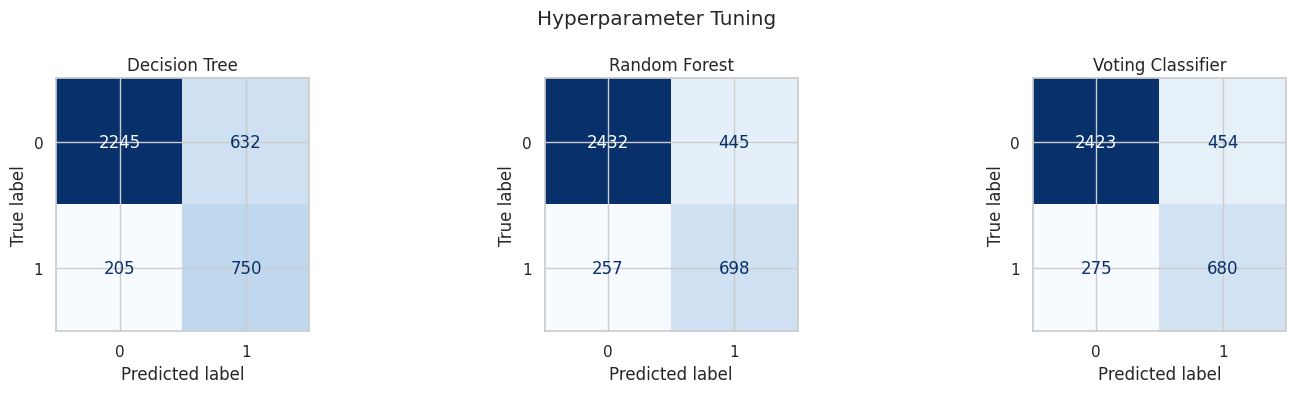

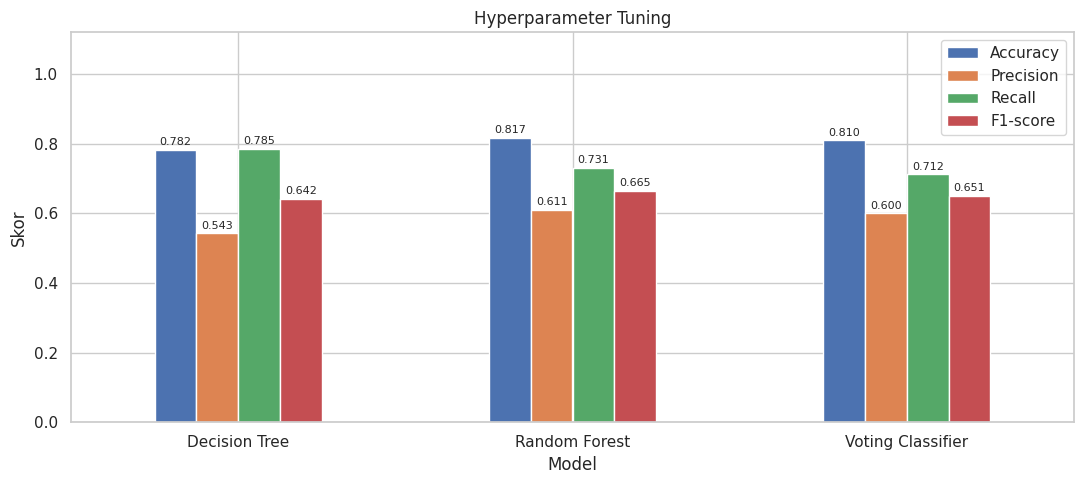

976

In [22]:
results_tuning,pred_tuning,score_tuning=evaluate_models(best_estimators,'Tuning',X_test,y_test)
plot_evaluation(results_tuning,pred_tuning,y_test,'Hyperparameter Tuning')
results_tuning.to_csv(OUTPUT_DIR/'hasil_tuning_modeling.csv',index=False)
cv_results.to_csv(OUTPUT_DIR/'hasil_cross_validation.csv',index=False)
best_summary.to_csv(OUTPUT_DIR/'ringkasan_cv.csv',index=False)
(OUTPUT_DIR/'best_params_tuning.json').write_text(json.dumps(best_params,indent=2),encoding='utf-8')

# Ringkasan terpadu — Sembilan eksperimen
Skenario Direct, Preprocessing, Tuning dibandingkan pada test set yang identik. Skor test merupakan evaluasi, bukan dasar pemilihan parameter. Model final dipilih berdasarkan F1 OOF training setelah optimasi threshold pada skenario aman. Tuning tidak dijamin meningkatkan F1 test karena generalisasi bersifat empiris. ROC-AUC/AP tidak dihitung untuk hard voting yang tidak menghasilkan probabilitas.

,Model,Skenario,Accuracy,Precision,Recall,F1-score,Balanced Accuracy,TN,FP,FN,TP,ROC-AUC,Average Precision
0,Decision Tree,Direct,0.8090,0.6026,0.6859,0.6415,0.7679,2445,432,300,655,0.7679,0.4916
1,Random Forest,Direct,0.9207,0.8720,0.7990,0.8339,0.8800,2765,112,192,763,0.9586,0.9074
2,Voting Classifier,Direct,0.8760,0.8279,0.6346,0.7184,0.7954,2751,126,349,606,NaN,NaN
3,Decision Tree,Preprocessing,0.7664,0.5305,0.5455,0.5379,0.6927,2416,461,434,521,0.6927,0.4027
4,Random Forest,Preprocessing,0.8319,0.6849,0.6031,0.6414,0.7555,2612,265,379,576,0.8607,0.6811
5,Voting Classifier,Preprocessing,0.7557,0.5068,0.7393,0.6014,0.7502,2190,687,249,706,NaN,NaN
6,Decision Tree,Tuning,0.7816,0.5427,0.7853,0.6418,0.7828,2245,632,205,750,0.8487,0.6721
7,Random Forest,Tuning,0.8168,0.6107,0.7309,0.6654,0.7881,2432,445,257,698,0.8650,0.6922
8,Voting Classifier,Tuning,0.8098,0.5996,0.7120,0.6510,0.7771,2423,454,275,680,0.8523,0.6763


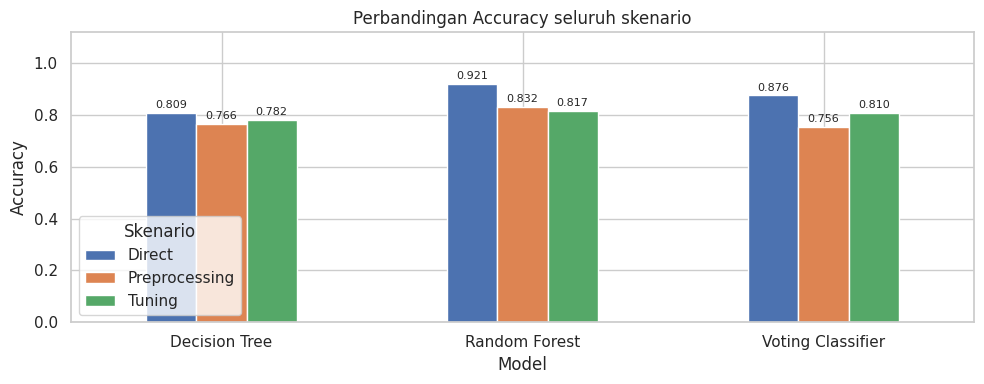

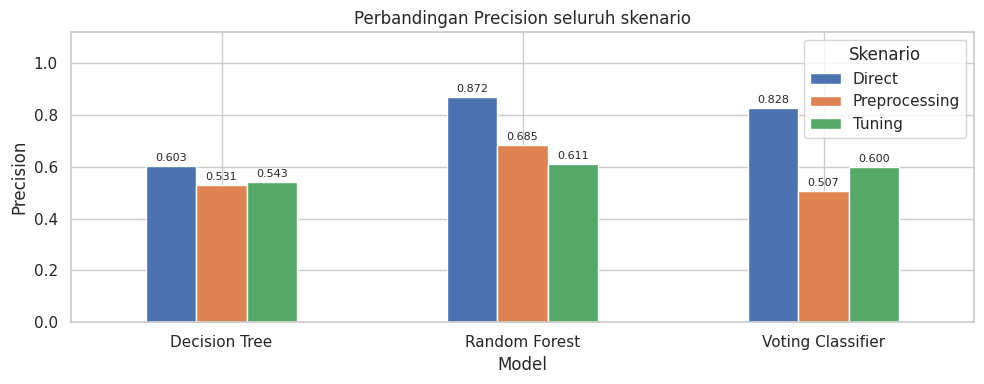

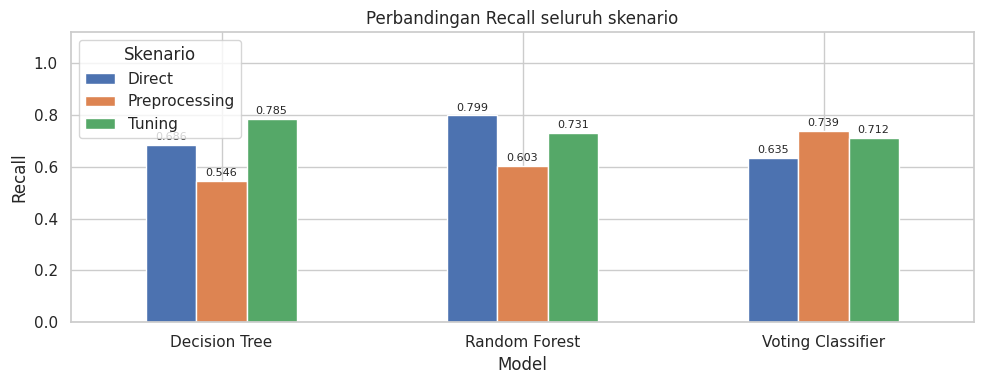

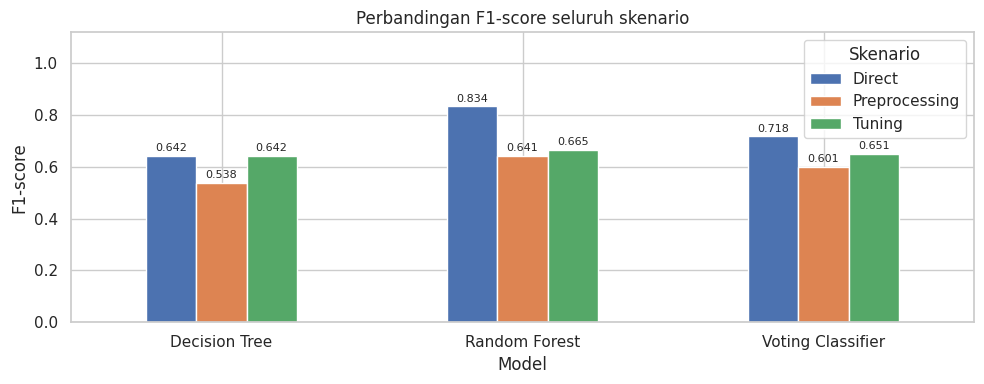

Skenario,Direct,Preprocessing,Tuning,Delta preprocessing-direct,Delta tuning-preprocessing
Model,,,,,
Decision Tree,0.6415,0.5379,0.6418,-0.1036,0.1039
Random Forest,0.8339,0.6414,0.6654,-0.1925,0.0240
Voting Classifier,0.7184,0.6014,0.6510,-0.1171,0.0497


Model aman terpilih (berdasarkan CV): Random Forest


,Model,Skenario,Accuracy,Precision,Recall,F1-score,Balanced Accuracy,TN,FP,FN,TP,ROC-AUC,Average Precision
1,Random Forest,Tuning,0.8168,0.6107,0.7309,0.6654,0.7881,2432,445,257,698,0.865,0.6922


In [23]:
comparison=pd.concat([results_direct,results_preprocessing,results_tuning],ignore_index=True)
assert len(comparison)==9 and not comparison.duplicated(['Model','Skenario']).any()
assert (comparison[['TN','FP','FN','TP']].sum(axis=1)==len(y_test)).all()
display(comparison.round(4))
for metric in METRICS:
    pivot=comparison.pivot(index='Model',columns='Skenario',values=metric)[['Direct','Preprocessing','Tuning']]
    ax=pivot.plot.bar(figsize=(10,4),rot=0)
    ax.set(title=f'Perbandingan {metric} seluruh skenario',ylabel=metric,ylim=(0,1.12))
    for container in ax.containers: ax.bar_label(container,fmt='%.3f',fontsize=8,padding=2)
    plt.tight_layout();plt.show()
change=comparison.pivot(index='Model',columns='Skenario',values='F1-score')
change['Delta preprocessing-direct']=change['Preprocessing']-change['Direct']
change['Delta tuning-preprocessing']=change['Tuning']-change['Preprocessing']
display(change.round(4))
print('Model aman terpilih (berdasarkan CV):',selected_name)
display(results_tuning.loc[results_tuning['Model']==selected_name].round(4))
comparison.to_csv(OUTPUT_DIR/'hasil_perbandingan_9_eksperimen.csv',index=False)
change.to_csv(OUTPUT_DIR/'perubahan_f1.csv')

## Diagnostik tambahan — Kurva ROC dan Precision-Recall

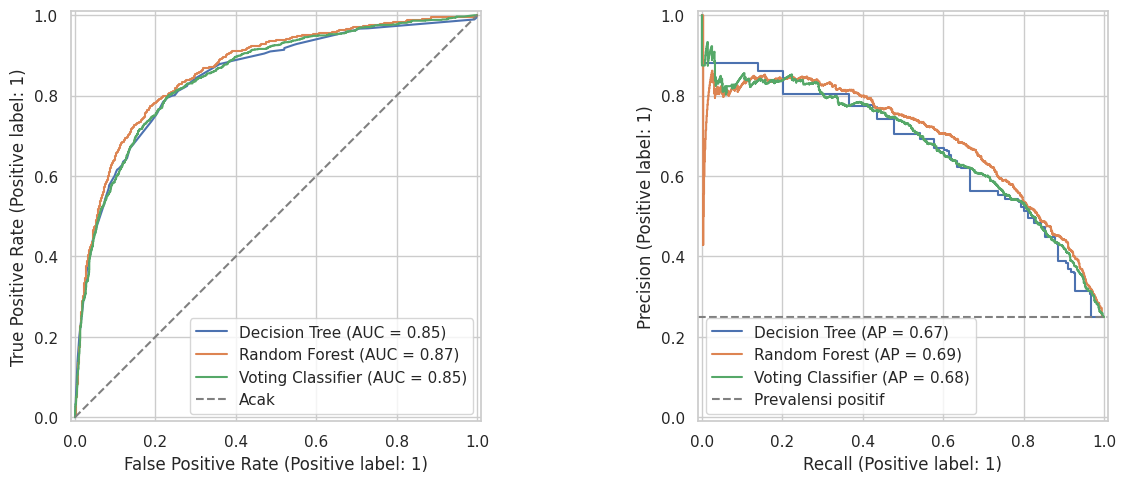

In [24]:
fig,axes=plt.subplots(1,2,figsize=(13,5))
for name,score in score_tuning.items():
    RocCurveDisplay.from_predictions(y_test,score,name=name,ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test,score,name=name,ax=axes[1])
axes[0].plot([0,1],[0,1],'--',color='gray',label='Acak')
axes[1].axhline(y_test.mean(),linestyle='--',color='gray',label='Prevalensi positif')
axes[0].legend();axes[1].legend();plt.tight_layout();plt.show()

## Interpretasi fitur model terpilih (validasi internal train)
Permutation importance mengacak satu fitur mentah pada validasi internal dan mengukur perubahan F1. Model di-fit ulang pada bagian training fold saja; bukan pada test. Model final yang telah dipilih tetap tidak berubah. Nilai pentingness negatif kecil dapat terjadi karena noise; bukan hubungan kausal. Fitur terlarang tidak perlu diuji karena dihapus pipeline.

,fitur,mean_delta_f1,std
18,skor_kepuasan_kerja,0.062986,0.004361
9,ukuran_perusahaan,0.056590,0.007817
2,indeks_pembangunan_kota,0.050470,0.004540
1,kode_kota,0.036198,0.003537
10,tipe_perusahaan,0.032197,0.002326
19,persentase_kenaikan_gaji,0.029938,0.002616
6,pendidikan,0.016337,0.000632
7,jurusan,0.014269,0.002482
11,jeda_pindah_kerja_thn,0.008752,0.000994
5,status_kuliah,0.008747,0.003074


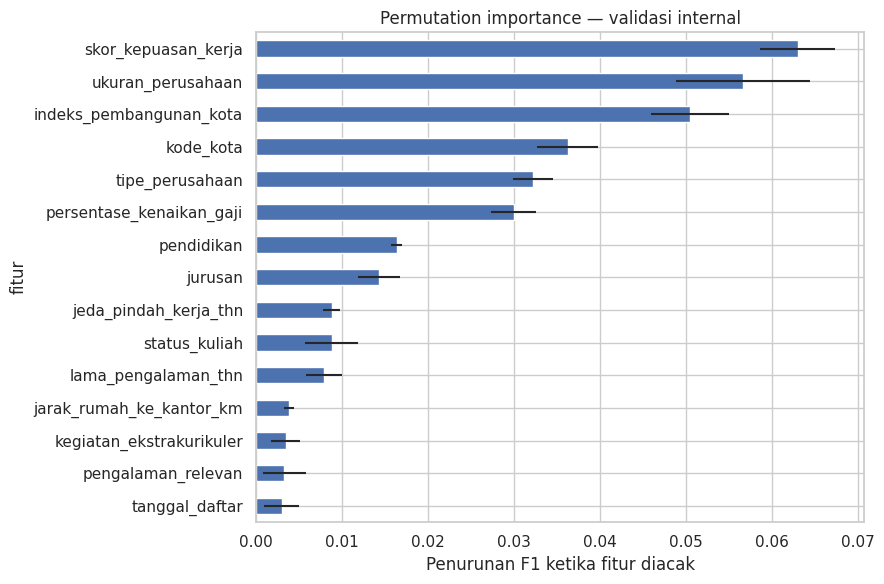

In [25]:
tr,va=cv_splits[0]
interpret_model=clone(selected_model).fit(X_train.iloc[tr],y_train.iloc[tr])
imp=permutation_importance(interpret_model,X_train.iloc[va],y_train.iloc[va],
    scoring=scoring['f1'],n_repeats=3,random_state=RANDOM_STATE,n_jobs=1)
importance=pd.DataFrame({'fitur':X_train.columns,'mean_delta_f1':imp.importances_mean,
    'std':imp.importances_std}).sort_values('mean_delta_f1',ascending=False)
display(importance)
importance.to_csv(OUTPUT_DIR/'permutation_importance.csv',index=False)
ax=importance.head(15).sort_values('mean_delta_f1').plot.barh(x='fitur',y='mean_delta_f1',xerr='std',legend=False,figsize=(9,6))
ax.set(title='Permutation importance — validasi internal',xlabel='Penurunan F1 ketika fitur diacak')
plt.tight_layout();plt.show()

## Kesimpulan dan keterbatasan

Lengkapi interpretasi dengan angka aktual setelah Run all:

1. Berapa baris deduplikasi, distribusi kelas, dan bukti tidak ada fingerprint yang bocor ke test/fold?
2. Teknik mana yang dipakai untuk missing, kategori, outlier, encoding, scaling, dan class imbalance? Mengapa belajar hanya dari training?
3. Apa parameter terbaik tiap model? Apakah F1 CV berubah, dan apakah ada gap train/validation yang besar?
4. Bandingkan F1, recall, precision, accuracy, false negative dan false positive untuk sembilan eksperimen; jika baseline menang di test, jelaskan risiko proxy dan jangan memilihnya untuk deployment dini.
5. Model mana yang terpilih berdasarkan CV, dan apa fitur yang penting berdasarkan evaluasi internal?
6. Data berasal dari periode dan populasi terbatas. Split acak berstrata mengukur generalisasi pada distribusi sama, bukan performa masa depan. Audit tambahan temporal (latih periode lama, uji periode baru) dan verifikasi waktu pencatatan label/fitur diperlukan sebelum deployment. Jangan menafsirkan skor probabilitas oversampling sebagai peluang yang terkalibrasi.
7. Fitur jenis kelamin, pendidikan dan kota perlu ditinjau dari sisi fairness dan tujuan bisnis; model ini untuk pembelajaran, bukan keputusan otomatis yang merugikan peserta.

**Ekspor:** CSV hasil direct, preprocessing, tuning, CV, perbandingan, audit partisi, audit preprocessing, importance, dan JSON parameter ada di folder `hasil_optimasi_terkontrol`. Pipeline final tersedia pada variabel `selected_model` di runtime. Untuk deployment lintas sesi, definisikan kelas/fungsi kustom di modul Python tersendiri sebelum menyimpan model; notebook ini tidak mengklaim telah menguji serialisasi lintas proses.
Referensi metodologi: Mazumdar et al. (2026), https://doi.org/10.1038/s41598-026-77466-w; AL-Ali et al. (2026), https://doi.org/10.1038/s41598-026-36424-2. Teknik dipilih sesuai soal; penelitian menggunakan dataset sumber yang diduga mendasari versi UAS, bukan versi 27 kolom yang identik.


In [26]:
print('File hasil eksperimen:')
for p in sorted(OUTPUT_DIR.iterdir()):
    print(p.name, f'({p.stat().st_size:,} bytes)')
print('PASS: 9 eksperimen, 3 model tuning, holdout dan fold bebas overlap profil.')

File hasil eksperimen:
audit_partisi.csv (712,758 bytes)
audit_preprocessing.csv (1,144 bytes)
best_params_tuning.json (976 bytes)
hasil_cross_validation.csv (22,119 bytes)
hasil_direct_modeling.csv (574 bytes)
hasil_perbandingan_9_eksperimen.csv (1,590 bytes)
hasil_preprocessing_modeling.csv (607 bytes)
hasil_tuning_modeling.csv (621 bytes)
perbandingan_sampling.csv (632 bytes)
permutation_importance.csv (1,460 bytes)
perubahan_f1.csv (427 bytes)
ringkasan_cv.csv (1,426 bytes)
threshold_oof.csv (408 bytes)
PASS: 9 eksperimen, 3 model tuning, holdout dan fold bebas overlap profil.


## Ringkasan hasil eksekusi aktual
Tabel dan ringkasan di bawah dihitung dari eksekusi notebook ini; tidak menggunakan angka hasil lama.


In [27]:
report=comparison[['Model','Skenario','Accuracy','Precision','Recall','F1-score','FN','TP']].copy()
display(report.round(4))
selected_row=results_tuning.loc[results_tuning.Model==selected_name].iloc[0]
print('Model final:',selected_name)
print('Parameter:',best_params[selected_name])
print('Accuracy:',round(selected_row.Accuracy,4),'Precision:',round(selected_row.Precision,4),'Recall:',round(selected_row.Recall,4),'F1:',round(selected_row['F1-score'],4))
print('TP:',selected_row.TP,'FN:',selected_row.FN)
print('Threshold:',selected_model.named_steps['model'].threshold)
print('PASS: sembilan eksperimen, CV lima fold, balancing training-only, threshold dipilih dari OOF.')


,Model,Skenario,Accuracy,Precision,Recall,F1-score,FN,TP
0,Decision Tree,Direct,0.8090,0.6026,0.6859,0.6415,300,655
1,Random Forest,Direct,0.9207,0.8720,0.7990,0.8339,192,763
2,Voting Classifier,Direct,0.8760,0.8279,0.6346,0.7184,349,606
3,Decision Tree,Preprocessing,0.7664,0.5305,0.5455,0.5379,434,521
4,Random Forest,Preprocessing,0.8319,0.6849,0.6031,0.6414,379,576
5,Voting Classifier,Preprocessing,0.7557,0.5068,0.7393,0.6014,249,706
6,Decision Tree,Tuning,0.7816,0.5427,0.7853,0.6418,205,750
7,Random Forest,Tuning,0.8168,0.6107,0.7309,0.6654,257,698
8,Voting Classifier,Tuning,0.8098,0.5996,0.7120,0.6510,275,680


Model final: Random Forest
Parameter: {'model__estimator__class_weight': None, 'model__estimator__max_depth': 14, 'model__estimator__max_features': 'sqrt', 'model__estimator__min_samples_leaf': 5, 'model__estimator__n_estimators': 100, 'model__ratio': 1.0, 'model__threshold': 0.5233544005173285}
Accuracy: 0.8168 Precision: 0.6107 Recall: 0.7309 F1: 0.6654
TP: 698 FN: 257
Threshold: 0.5233544005173285
PASS: sembilan eksperimen, CV lima fold, balancing training-only, threshold dipilih dari OOF.
